# 1. Introduction and Data Quality Framework

## 1.1 Objective

The objective of this analysis is to identify and flag data quality issues in the herbaceous vegetation survey data and assess whether the collected data is consistent with the **SOP-defined sampling design, reference data, and relational structure**.

The QA/QC process will assess:

- Data completeness and consistency
- Referential integrity between related datasets
- Validity of identifiers and controlled values
- Sampling effort and quadrat coverage
- Compliance with the prescribed survey structure
- Field-level data validity
- Spatial consistency of transect and plot locations
- The integrity of joins and transformations used to create the analytical dataset

The analysis will also produce the required outputs for the data quality report:

1. Survey-level summary
2. Plot-level summary
3. Assessment of sampling effort
4. Map of transect locations

A key principle throughout the analysis is that **data errors will be flagged, not corrected**. The raw ODK data will remain unchanged, with QA/QC results maintained as separate derived fields or datasets.

---

## 1.2 Data and Relational Structure

The vegetation survey data is collected in the field using ODK and consists of related datasets representing the different components of the survey.

The analysis will use the available:

- Plot registration data
- Herbaceous vegetation survey data
- Repeating quadrat observations
- Entity and reference tables
- ODK identifiers and metadata

The ODK form contains parent-child relationships between survey records and their associated quadrat observations. These relationships will be established using the identifiers captured by ODK, such as `PARENT_KEY`.

The analytical dataset will therefore be constructed through controlled **joins and transformations**. These operations will subsequently be validated to ensure that records are not incorrectly linked, duplicated, lost, or otherwise altered in structure during processing.

---

## 1.3 Data Quality and Validation Workflow

The QA/QC process will follow the sequence below.

### 1. Raw ODK Data

The raw ODK outputs will be treated as the source data for the analysis.

Key inputs include:

- Plot registration records
- Herbaceous vegetation survey records
- Repeating quadrat records
- Entity and reference tables
- ODK identifiers and metadata

### 2. Data Profiling

The raw datasets will first be profiled to understand their structure and identify general quality issues.

Checks will include:

- Record and field counts
- Data types
- Missing values
- Duplicate records
- Unique values
- Unexpected values
- Identifier completeness
- Basic structural consistency

### 3. Join and Transformation

The required analytical structure will then be created by:

- Linking plot registration records to vegetation survey records
- Establishing parent-child relationships
- Transforming repeating quadrat records where required
- Joining species and other reference/entity tables
- Creating derived analytical and QA/QC fields

### 4. Join and Transformation Validation

The resulting datasets will be checked to ensure that the transformations have preserved the integrity of the source data.

Checks will include:

- Valid parent-child relationships
- Unmatched records
- Records lost during joins
- Records duplicated during joins
- Unexpected one-to-many or many-to-many relationships
- Changes in record counts before and after transformations
- Identifier uniqueness
- Consistency between the transformed structure and the ODK form

### 5. Reference and Entity Validation

Survey values will be compared against the supplied reference and entity lists.

Examples include:

- areas
- centroids
- ecosystem_types
- project_team
- projects
- species
- species_extra
- species_extra_ids
- surveys
- transport
- vegplots

Invalid or unexpected values will be flagged rather than corrected.

### 6. Sampling Effort and SOP Compliance

The observed survey structure will be compared with the sampling requirements defined in the SOP.

Checks will include:

- Expected number of quadrats
- Observed number of quadrats
- Missing quadrats
- Duplicate quadrats
- Unexpected quadrat identifiers
- Incomplete surveys
- Plot and survey coverage
- Other deviations from the prescribed sampling design

This ensures that the QA/QC process assesses not only the validity of individual data values, but also whether the **required sampling activity was completed and captured correctly**.

### 7. Record-Level QA/QC

Individual records and observations will be evaluated against specific validation rules.

Potential QA/QC flags include:

- `species_valid`
- `plot_valid`
- `transect_valid`
- `quadrat_valid`
- `coordinates_valid`
- `cover_valid`
- `date_valid`
- `duplicate_flag`
- `missing_required_field`

### 8. Overall QA Status

Individual QA/QC results will be combined to provide an overall status for the relevant survey, plot, or observation.

| QA Status | Meaning |
|---|---|
| `PASS` | No relevant QA/QC issues identified |
| `REVIEW` | One or more issues require investigation |
| `FAIL` | A critical structural, sampling, or data-quality requirement has not been met |

### 9. Spatial QA

Spatial checks will assess the geographic component of the survey.

These will include:

- Missing coordinates
- Invalid coordinate values
- Latitude and longitude range checks
- Potential spatial outliers
- Plot and transect spatial relationships
- Spatial consistency between related records

`GeoPandas` will be used where appropriate for spatial processing and visualisation.

### 10. Data Quality Report

The validated outputs will be used to produce:

- Survey-level summary
- Plot-level summary
- Sampling effort assessment
- Transect location map

### 11. Automation Specification

The final analytical logic will be translated into a specification for implementation on the NS Analytics platform.

This will define:

- Required source tables
- Table relationships
- Join keys
- Transformation logic
- Reference tables
- Validation rules
- Sampling-effort calculations
- QA/QC flags
- Spatial checks
- Summary metrics
- Dashboard outputs

---

## 1.4 Data Profiling and Quality Assessment

Data profiling provides the initial assessment of the raw ODK outputs before more specific validation rules are applied.

The profiling stage will examine:

- Dataset dimensions
- Field names and data types
- Missing and incomplete values
- Duplicate records
- Unique values and distributions
- Identifier completeness
- Date and time fields
- Structural consistency

The results of this stage will help determine the appropriate validation rules and provide baseline record counts against which subsequent joins and transformations can be assessed.

---

## 1.5 Join and Transformation Validation

Joins and transformations are an important part of the QA/QC process because errors can be introduced during data preparation even when the original ODK records are valid.

For each major transformation, the following questions will be considered:

- Does every vegetation survey link to a valid registered plot?
- Are all parent-child relationships valid?
- Are there survey records without a corresponding parent record?
- Are there registered plots without the expected survey?
- Are records duplicated as a result of a join?
- Are any records lost during transformation?
- Are expected one-to-many relationships preserved?
- Does the number of quadrat observations remain consistent before and after transformation?
- Are identifiers unique at the appropriate level?
- Does the resulting analytical structure match the ODK form and SOP?

A technically successful join does not necessarily mean that the resulting dataset is correct. Therefore, **the join and transformation process itself will be quality-assured**.

---

## 1.6 Sampling Effort and SOP Compliance

Sampling effort is assessed by comparing the survey data actually submitted with the sampling structure prescribed by the SOP.

The analysis will identify:

- Expected sampling units
- Observed sampling units
- Missing sampling units
- Duplicate sampling units
- Unexpected sampling units
- Incomplete surveys
- Coverage gaps
- Other deviations from the prescribed sampling design

This provides an important distinction between **field-level data validity** and **sampling-level data quality**.

For example, an observation may contain a valid species name, valid coordinate, and valid date but still contribute to a sampling-quality issue if the required quadrat was not surveyed or was recorded more than once.

---

## 1.7 Record-Level QA/QC

Each validation rule will generate an explicit QA/QC flag.

The original observation will be retained alongside the result of the validation rule. This allows issues to be traced back to the source record without modifying the underlying data.

For example:

```text
species_valid = True
coordinates_valid = True
quadrat_valid = False
duplicate_flag = False

In [14]:
# ============================================================
# 1. IMPORTS, DEPENDENCIES AND CONFIGURATION
# ============================================================

import os
import sys
import subprocess
import importlib


# ------------------------------------------------------------
# Required Python packages
# ------------------------------------------------------------

REQUIRED_PACKAGES = {
    "pandas": "pandas",
    "numpy": "numpy",
    "openpyxl": "openpyxl",
    "geopandas": "geopandas",
    "matplotlib": "matplotlib",
    "shapely": "shapely",
}


# ------------------------------------------------------------
# Install missing packages automatically
# ------------------------------------------------------------

def install_if_missing(package_name, import_name):
    """
    Check whether a package is installed.
    If missing, install it into the current
    Python/Jupyter environment.
    """

    try:
        importlib.import_module(import_name)
        print(f"✓ {package_name} already installed")

    except ImportError:
        print(f"Installing {package_name}...")

        subprocess.check_call([
            sys.executable,
            "-m",
            "pip",
            "install",
            package_name
        ])

        print(f"✓ {package_name} installed")


# ------------------------------------------------------------
# Check all dependencies
# ------------------------------------------------------------

print("Checking required packages...\n")

for package_name, import_name in REQUIRED_PACKAGES.items():
    install_if_missing(package_name, import_name)


# ------------------------------------------------------------
# Import packages
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import openpyxl
import geopandas as gpd
import matplotlib.pyplot as plt

from shapely.geometry import Point
from pathlib import Path

# ============================================================
# PROJECT CONFIGURATION
# ============================================================
DATA_DIR = Path(
    r"C:\Users\HP\Downloads\Take Home Project\Data Vegetation\ODK Data Exports"
)

OUTPUT_DIR = DATA_DIR / "output"

OUTPUT_DIR.mkdir(exist_ok=True)
# ------------------------------------------------------------
# Source files
# ------------------------------------------------------------

PLOTS_FILE = DATA_DIR / "register_vegetation_plots.csv"
SURVEY_FILE = DATA_DIR / "herbaceous_veg_survey.csv"
QUADRAT_FILE = DATA_DIR / "herbaceous_veg_survey-quadrat_repeat.csv"
SPECIES_REPEAT_FILE = DATA_DIR / "herbaceous_veg_survey-additional_species_repeat.csv"


# ============================================================
# ENVIRONMENT CHECK
# ============================================================

print("\nEnvironment:")
print(f"Python: {sys.executable}")
print(f"Version: {sys.version.split()[0]}")

SOURCE_FILES = {
    "Plot registration": PLOTS_FILE,
    "Main vegetation survey": SURVEY_FILE,
    "Quadrat repeat": QUADRAT_FILE,
    "Additional species repeat": SPECIES_REPEAT_FILE,
}

print("Checking data directory...\n")

if DATA_DIR.exists():

    print("✓ Data directory exists.")
    print("\nFiles found:\n")

    for file in DATA_DIR.iterdir():
        print(file.name)

else:

    print("✗ Data directory does not exist:")
    print(DATA_DIR)



Checking required packages...

✓ pandas already installed
✓ numpy already installed
✓ openpyxl already installed
✓ geopandas already installed
✓ matplotlib already installed
✓ shapely already installed

Environment:
Python: C:\Users\HP\anaconda3\python.exe
Version: 3.13.9
Checking data directory...

✓ Data directory exists.

Files found:

herbaceous_veg_survey-additional_species_repeat.csv
herbaceous_veg_survey-quadrat_repeat.csv
herbaceous_veg_survey.csv
output
register_vegetation_plots.csv


In [15]:

# ============================================================
# 2. LOAD RAW ODK DATA
# ============================================================

plots = pd.read_csv(PLOTS_FILE)
survey = pd.read_csv(SURVEY_FILE)
quadrat_repeat = pd.read_csv(QUADRAT_FILE)
species_repeat = pd.read_csv(SPECIES_REPEAT_FILE)


# ============================================================
# BASIC STRUCTURE
# ============================================================

datasets = {
    "Plot registration": plots,
    "Main vegetation survey": survey,
    "Quadrat repeat": quadrat_repeat,
    "Additional species repeat": species_repeat,
}


for name, df in datasets.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(f"Rows:    {len(df):,}")
    print(f"Columns: {len(df.columns)}")

    print("\nColumn names:")
    print(df.columns.tolist())

# ============================================================
# 2.1 DATA TYPES
# ============================================================

for name, df in datasets.items():

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    print(df.dtypes)


Plot registration
Rows:    31
Columns: 82

Column names:
['SubmissionDate', 'note_overview', 'field_team_specifics-selected_transport_type_uuid', 'field_team_specifics-transport_type_label', 'field_team_specifics-selected_project_team_uuid_multi', 'field_team_specifics-recorder_uuid', 'field_team_specifics-recorder_label', 'field_team_specifics-default_survey_uuids', 'survey_begin-start_time', 'survey_begin-survey_year', 'survey_begin-selected_survey_uuid_multi', 'survey_begin-get_survey_label_multi', 'survey_begin-project_label', 'survey_begin-project_abbr', 'survey_begin-area_label', 'survey_begin-baseline_year', 'survey_begin-replicate_index', 'survey_begin-replicate', 'survey_begin-note_parent_labels', 'plot_selection-selected_plot_uuid', 'plot_selection-plot_label', 'plot_selection-plot_name', 'plot_selection-geohash', 'plot_selection-stratum_label', 'plot_selection-sample_status', 'plot_selection-is_plot_viable', 'plot_selection-plot_establishment_notes', 'plot_metadata-selected

In [16]:
# ============================================================
# 3. LOAD ENTITY / REFERENCE TABLES
# ============================================================

ENTITY_DIR = Path(
    r"C:\Users\HP\Downloads\Take Home Project\Data Vegetation\Entity lists"
)


# ------------------------------------------------------------
# Check entity directory
# ------------------------------------------------------------

print("Entity directory:")
print(ENTITY_DIR)

print(f"\nDirectory exists: {ENTITY_DIR.exists()}")


# ============================================================
# LOAD ALL ENTITY / REFERENCE CSV FILES
# ============================================================

entity_tables = {}

if ENTITY_DIR.exists():

    entity_files = sorted(ENTITY_DIR.glob("*.csv"))

    print(f"\nEntity CSV files found: {len(entity_files)}")

    for file_path in entity_files:

        # Use filename without extension as dictionary key
        table_name = file_path.stem

        # Load table
        entity_tables[table_name] = pd.read_csv(file_path)

        print(
            f"✓ {file_path.name}"
            f" | Rows: {len(entity_tables[table_name]):,}"
            f" | Columns: {len(entity_tables[table_name].columns)}"
        )

else:

    print("✗ Entity directory not found.")

    # ============================================================
# CREATE DATAFRAME VARIABLES FROM ENTITY TABLE NAMES
# ============================================================

for name, df in entity_tables.items():
    globals()[name] = df

print("Entity tables are now available as variables:")
print(list(entity_tables.keys()))

Entity directory:
C:\Users\HP\Downloads\Take Home Project\Data Vegetation\Entity lists

Directory exists: True

Entity CSV files found: 11
✓ areas.csv | Rows: 1 | Columns: 10
✓ centroids.csv | Rows: 51 | Columns: 21
✓ ecosystem_types.csv | Rows: 5 | Columns: 10
✓ project_team.csv | Rows: 6 | Columns: 13
✓ projects.csv | Rows: 1 | Columns: 11
✓ species.csv | Rows: 370 | Columns: 21
✓ species_extra.csv | Rows: 250 | Columns: 14
✓ species_extra_ids.csv | Rows: 109 | Columns: 11
✓ surveys.csv | Rows: 4 | Columns: 15
✓ transport.csv | Rows: 5 | Columns: 10
✓ vegplots.csv | Rows: 31 | Columns: 19
Entity tables are now available as variables:
['areas', 'centroids', 'ecosystem_types', 'project_team', 'projects', 'species', 'species_extra', 'species_extra_ids', 'surveys', 'transport', 'vegplots']


In [17]:
# ============================================================
# 2.7 IDENTIFIER COMPLETENESS AND UNIQUENESS
# ============================================================

for name, df in datasets.items():

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    id_columns = [
        col for col in df.columns
        if any(term in col.lower() for term in ["id", "uuid", "key"])
    ]

    for col in id_columns:

        missing = df[col].isna().sum()
        unique = df[col].nunique(dropna=True)
        total = len(df)

        print(f"\n{col}")
        print(f"  Total records:       {total:,}")
        print(f"  Missing:             {missing:,}")
        print(f"  Unique non-null:     {unique:,}")
        print(f"  Duplicate non-null:  {total - missing - unique:,}")


Plot registration

field_team_specifics-selected_transport_type_uuid
  Total records:       31
  Missing:             0
  Unique non-null:     1
  Duplicate non-null:  30

field_team_specifics-selected_project_team_uuid_multi
  Total records:       31
  Missing:             0
  Unique non-null:     1
  Duplicate non-null:  30

field_team_specifics-recorder_uuid
  Total records:       31
  Missing:             0
  Unique non-null:     2
  Duplicate non-null:  29

field_team_specifics-default_survey_uuids
  Total records:       31
  Missing:             0
  Unique non-null:     1
  Duplicate non-null:  30

survey_begin-selected_survey_uuid_multi
  Total records:       31
  Missing:             0
  Unique non-null:     2
  Duplicate non-null:  29

plot_selection-selected_plot_uuid
  Total records:       31
  Missing:             0
  Unique non-null:     31
  Duplicate non-null:  0

plot_metadata-selected_ecosystem_type_uuid
  Total records:       31
  Missing:             1
  Unique non-

In [18]:
# ============================================================
# 2.12 STRUCTURAL PROFILE SUMMARY
# ============================================================

profile_summary = []

for name, df in datasets.items():

    profile_summary.append({
        "dataset": name,
        "records": len(df),
        "fields": len(df.columns),
        "exact_duplicates": df.duplicated().sum(),
        "empty_rows": df.isna().all(axis=1).sum(),
        "empty_columns": df.isna().all(axis=0).sum(),
    })

profile_summary = pd.DataFrame(profile_summary)

display(profile_summary)

,dataset,records,fields,exact_duplicates,empty_rows,empty_columns
0,Plot registration,31,82,0,0,7
1,Main vegetation survey,32,52,0,0,9
2,Quadrat repeat,640,21,0,0,4
3,Additional species repeat,1296,30,0,0,8


Survey Dataset

In [19]:
# ============================================================
# 3.1 SURVEY → QUADRAT JOIN
# ============================================================

survey_quadrat = survey.merge(
    quadrat_repeat,
    left_on="KEY",
    right_on="PARENT_KEY",
    how="left",
    suffixes=("_survey", "_quadrat"),
    indicator=True
)

print("Survey records:", survey["KEY"].nunique())
print("Quadrat records:", quadrat_repeat["KEY"].nunique())
print("Joined rows:", len(survey_quadrat))

display(
    survey_quadrat["_merge"]
    .value_counts()
    .rename_axis("join_status")
    .reset_index(name="records")
)

Survey records: 32
Quadrat records: 640
Joined rows: 640


,join_status,records
0,both,640
1,left_only,0
2,right_only,0


In [20]:
# ============================================================
# 3.2 QUADRAT → ADDITIONAL SPECIES JOIN
# ============================================================

survey_quadrat_species = survey_quadrat.merge(
    species_repeat,
    left_on="KEY_quadrat",
    right_on="PARENT_KEY",
    how="left",
    suffixes=("", "_species"),
    indicator="species_merge"
)

print("Final joined rows:", len(survey_quadrat_species))

display(
    survey_quadrat_species["species_merge"]
    .value_counts()
    .rename_axis("join_status")
    .reset_index(name="records")
)

Final joined rows: 1362


,join_status,records
0,both,1296
1,left_only,66
2,right_only,0


In [21]:
# ============================================================
# 3.3 INVESTIGATE QUADRATS WITHOUT ADDITIONAL-SPECIES RECORDS
# ============================================================

left_only_quadrats = survey_quadrat_species[
    survey_quadrat_species["species_merge"] == "left_only"
].copy()

print(
    "Quadrats without linked additional-species records:",
    left_only_quadrats["KEY_quadrat"].nunique()
)

display(
    left_only_quadrats[
        [
            "KEY_survey",
            "KEY_quadrat",
            "quadrat_number",
            "herbs_present",
            "herb_species-selected_herb_species_uuids",
            "herb_species-count_herb_species",
            "additional_species_present",
            "species_list-all_species_list"
        ]
    ].head(10)
)

Quadrats without linked additional-species records: 66


,KEY_survey,KEY_quadrat,quadrat_number,herbs_present,herb_species-selected_herb_species_uuids,herb_species-count_herb_species,additional_species_present,species_list-all_species_list
46,uuid:599e04cf-832f-4535-8305-967918d12026,uuid:599e04cf-832f-4535-8305-967918d12026/obse...,18,yes,3c3ff64b-92fd-4d60-9022-63a7c599e108 cdc30e17-...,4.0,no,Aristida adscensionis<br/>Indigofera schimperi...
52,uuid:c6cc7231-7af6-4bc5-b281-565c53f21763,uuid:c6cc7231-7af6-4bc5-b281-565c53f21763/obse...,2,yes,008f3da5-910b-4d85-a844-c5ab8b75fcd8 883b0fcc-...,2.0,no,Aristida adscensionis<br/>Commelina benghalensis
93,uuid:c6cc7231-7af6-4bc5-b281-565c53f21763,uuid:c6cc7231-7af6-4bc5-b281-565c53f21763/obse...,19,yes,008f3da5-910b-4d85-a844-c5ab8b75fcd8,1.0,yes,Aristida adscensionis
142,uuid:49d73df9-2d36-4a1e-aa29-6f94f23a7513,uuid:49d73df9-2d36-4a1e-aa29-6f94f23a7513/obse...,19,yes,1dc71d7e-f47b-47f5-8dbb-7e82c9867534,1.0,no,Melinis repens
298,uuid:938c15e5-c942-49aa-8e6d-9633189870ff,uuid:938c15e5-c942-49aa-8e6d-9633189870ff/obse...,2,yes,f407986d-94a5-4fa9-a058-b9f183687960 4c3c1743-...,3.0,yes,Melinis repens<br/>Perotis patens<br/>Sida cor...
362,uuid:8e5f5c9d-d697-4358-b766-db4a41f28c3e,uuid:8e5f5c9d-d697-4358-b766-db4a41f28c3e/obse...,7,yes,8fb56826-0f75-4fd9-afc2-f995f704dbcf,1.0,no,Hibiscus micranthus
427,uuid:4137458f-31e5-4355-b4ad-47858fb11503,uuid:4137458f-31e5-4355-b4ad-47858fb11503/obse...,17,no,NaN,NaN,NaN,NaN
431,uuid:4137458f-31e5-4355-b4ad-47858fb11503,uuid:4137458f-31e5-4355-b4ad-47858fb11503/obse...,20,yes,9ab8c574-90c7-4055-98e9-f58b576de7e2,1.0,no,Urochloa mosambicensis
446,uuid:430e85a3-44ce-45f4-9974-c6a61569e78b,uuid:430e85a3-44ce-45f4-9974-c6a61569e78b/obse...,7,yes,cdc30e17-bf4f-4243-9c0b-0698d69bc373 42b6fdde-...,3.0,no,Ipomoea coptica<br/>Commelina benghalensis<br/...
447,uuid:430e85a3-44ce-45f4-9974-c6a61569e78b,uuid:430e85a3-44ce-45f4-9974-c6a61569e78b/obse...,8,yes,42b6fdde-7193-48e4-8a16-488eae05fab9 883b0fcc-...,2.0,no,Ipomoea coptica<br/>Commelina benghalensis


In [22]:
# Check the characteristics of quadrats without additional-species records

left_only_quadrats[
    [
        "herbs_present",
        "additional_species_present"
    ]
].value_counts(dropna=False)

herbs_present  additional_species_present
yes            no                            49
               yes                           10
no             NaN                            7
Name: count, dtype: int64

### Interpretation of `left_only` quadrats

The 66 `left_only` records represent quadrats in the survey/quadrat table that do not have a corresponding record in the additional-species repeat table.

These records should **not automatically be treated as data errors**. Inspection shows that the affected quadrats can have known herbaceous species recorded, while `additional_species_present` is recorded as `no`. In this situation, the absence of a child record is consistent with the survey structure: no additional species were entered for that quadrat.

Therefore, the 66 `left_only` records are treated as **expected absence rather than failed referential integrity**. They should not be removed or corrected. The QA/QC process should distinguish between an expected absence of child records and a genuinely missing or broken relationship.

In [23]:
# ============================================================
# 4.1 SURVEY-LEVEL SUMMARY AND QA/QC
# One row = one survey submission
# ============================================================

survey_summary = (
    survey_quadrat_species
    .groupby("KEY_survey", as_index=False)
    .agg(
        plot_id=("plot_selection-selected_plot_uuid", "first"),
        plot_name=("plot_selection-plot_name", "first"),
        field_team=("field_team_specifics-recorder_label", "first"),
        survey_start=("survey_begin-start_time", "first"),
        survey_status=("plot_selection-plot_status", "first"),
        declared_quadrats=("observations-quadrat_repeat_count", "first"),
        declared_quadrats_with_species=("survey_end-quadrats_with_species", "first"),
        quadrat_check=("survey_end-quadrat_check", "first"),
        review_state=("ReviewState", "first")
    )
)

# ------------------------------------------------------------
# Actual quadrat records
# ------------------------------------------------------------

actual_quadrats = (
    survey_quadrat_species[
        survey_quadrat_species["KEY_quadrat"].notna()
    ]
    .groupby("KEY_survey")
    .agg(
        quadrats_recorded=("KEY_quadrat", "nunique")
    )
    .reset_index()
)

survey_summary = survey_summary.merge(
    actual_quadrats,
    on="KEY_survey",
    how="left"
)

# ------------------------------------------------------------
# Quadrats with species recorded
# ------------------------------------------------------------

quadrats_with_species = (
    survey_quadrat_species[
        survey_quadrat_species["KEY_quadrat"].notna()
    ]
    .assign(
        species_list_present=
            survey_quadrat_species["species_list-all_species_list"]
            .fillna("")
            .astype(str)
            .str.strip()
            .ne("")
    )
    .groupby("KEY_survey")
    .agg(
        quadrats_with_species_recorded=("species_list_present", "sum")
    )
    .reset_index()
)

survey_summary = survey_summary.merge(
    quadrats_with_species,
    on="KEY_survey",
    how="left"
)

# ------------------------------------------------------------
# Additional species records
# ------------------------------------------------------------

additional_species_counts = (
    survey_quadrat_species[
        survey_quadrat_species["species_merge"] == "both"
    ]
    .groupby("KEY_survey")
    .agg(
        additional_species_records=("KEY", "count")
    )
    .reset_index()
)

survey_summary = survey_summary.merge(
    additional_species_counts,
    on="KEY_survey",
    how="left"
)

# ------------------------------------------------------------
# Missing values → zero where absence is expected
# ------------------------------------------------------------

survey_summary["quadrats_recorded"] = (
    survey_summary["quadrats_recorded"]
    .fillna(0)
    .astype(int)
)

survey_summary["quadrats_with_species_recorded"] = (
    survey_summary["quadrats_with_species_recorded"]
    .fillna(0)
    .astype(int)
)

survey_summary["additional_species_records"] = (
    survey_summary["additional_species_records"]
    .fillna(0)
)

# ------------------------------------------------------------
# QA/QC FLAGS
# ------------------------------------------------------------

survey_summary["quadrat_count_mismatch_flag"] = (
    survey_summary["declared_quadrats"]
    != survey_summary["quadrats_recorded"]
)

survey_summary["no_quadrat_records_flag"] = (
    survey_summary["quadrats_recorded"] == 0
)

survey_summary["duplicate_plot_id_flag"] = (
    survey_summary["plot_id"]
    .duplicated(keep=False)
)

qa_columns = [
    "quadrat_count_mismatch_flag",
    "no_quadrat_records_flag",
    "duplicate_plot_id_flag"
]

survey_summary["qa_issue_flag"] = (
    survey_summary[qa_columns].any(axis=1)
)

# ------------------------------------------------------------
# Display final survey-level table
# ------------------------------------------------------------

display(survey_summary)

,KEY_survey,plot_id,plot_name,field_team,survey_start,survey_status,declared_quadrats,declared_quadrats_with_species,quadrat_check,review_state,quadrats_recorded,quadrats_with_species_recorded,additional_species_records,quadrat_count_mismatch_flag,no_quadrat_records_flag,duplicate_plot_id_flag,qa_issue_flag
0,uuid:2439f628-f86d-4770-98d1-ae7b99a4d91f,fd4fed55-b92c-425a-9f66-1b15427f9ce0,SavMon_LW_Plot_26,Grace,2026-05-22T11:05:16.453+02:00,NaN,20,19,NaN,None,20,44,43,False,False,False,False
1,uuid:359a5da6-d237-4203-b838-8596bdbd4935,edf62d32-bf13-47ec-ad1c-356bed17570a,SavMon_LW_Plot_08,Sam,2026-05-19T10:42:21.229+02:00,NaN,20,19,NaN,None,20,43,42,False,False,False,False
2,uuid:3865525f-1d45-40fc-83ca-7e30fafe6b54,d17cbd2e-4c3a-4a01-bd96-59b63764c5d5,SavMon_LW_Plot_10,Grace,2026-05-21T10:29:48.099+02:00,NaN,20,18,NaN,None,20,36,34,False,False,False,False
3,uuid:4137458f-31e5-4355-b4ad-47858fb11503,3b4fc821-0b06-4e19-b17b-1330d0dbaf90,SavMon_LW_Plot_04,Grace,2026-05-25T14:06:27.872+02:00,NaN,20,18,NaN,None,20,38,37,False,False,False,False
4,uuid:430e85a3-44ce-45f4-9974-c6a61569e78b,5aafaaed-0656-401d-aea7-3b18bf206c7f,SavMon_LW_Plot_07,Grace,2026-05-24T15:38:45.517+02:00,NaN,20,17,NaN,None,20,41,38,False,False,False,False
5,uuid:49d73df9-2d36-4a1e-aa29-6f94f23a7513,8070570d-64ca-405a-802d-4d721fdc2fe9,SavMon_LW_Plot_21,Grace,2026-05-26T09:44:02.068+02:00,NaN,20,19,NaN,None,20,48,47,False,False,True,True
6,uuid:54452130-d92e-4996-a0d7-9401811b9ed7,8b86dcfb-e97f-4829-9582-0e0aa4d138cd,SavMon_LW_Plot_15,Grace,2026-05-24T14:00:46.700+02:00,NaN,20,17,NaN,None,20,32,29,False,False,False,False
7,uuid:599e04cf-832f-4535-8305-967918d12026,b1e1fc7f-afbd-404c-bd6c-55b172d722df,SavMon_LW_Plot_16,Grace,2026-05-27T09:41:43.843+02:00,NaN,20,19,NaN,None,20,51,50,False,False,False,False
8,uuid:5d242bf2-8888-4eb0-9082-431482177425,dbd003da-4c6a-46a3-95be-ce6febaaab89,SavMon_LW_Plot_05,Grace,2026-05-22T08:27:48.309+02:00,NaN,20,12,NaN,None,20,23,16,False,False,False,False
9,uuid:7ae61d55-3663-422e-aad2-9104b56c9a47,f3fb5ba5-0209-4ac4-9666-8023f28a8918,SavMon_LW_Plot_06,Grace,2026-05-23T08:37:13.454+02:00,NaN,20,20,NaN,None,20,52,52,False,False,False,False


In [24]:
# ============================================================
# SURVEY-LEVEL QA/QC SUMMARY
# ============================================================

qa_flag_columns = [
    "quadrat_count_mismatch_flag",
    "no_quadrat_records_flag",
    "duplicate_plot_id_flag"
]

total_surveys = len(survey_summary)

survey_qa_summary = pd.DataFrame({
    "QA check": [
        "Total survey records",
        "Quadrat count mismatch",
        "No quadrat records",
        "Duplicate plot ID",
        "Surveys with any QA flag",
        "Total QA flags"
    ],
    "Number flagged": [
        total_surveys,
        survey_summary["quadrat_count_mismatch_flag"].sum(),
        survey_summary["no_quadrat_records_flag"].sum(),
        survey_summary["duplicate_plot_id_flag"].sum(),
        survey_summary[qa_flag_columns].any(axis=1).sum(),
        survey_summary[qa_flag_columns].sum().sum()
    ]
})

survey_qa_summary["% of surveys"] = (
    survey_qa_summary["Number flagged"]
    / total_surveys
    * 100
).round(1)

display(survey_qa_summary)

,QA check,Number flagged,% of surveys
0,Total survey records,32,100.0
1,Quadrat count mismatch,0,0.0
2,No quadrat records,0,0.0
3,Duplicate plot ID,4,12.5
4,Surveys with any QA flag,4,12.5
5,Total QA flags,4,12.5


In [25]:
# ============================================================
# PLOT-LEVEL SUMMARY AND QA/QC
# One row = one registered plot
# ============================================================

plot_summary = (
    plots[
        [
            "plot_selection-selected_plot_uuid",
            "plot_selection-plot_name",
            "plot_selection-stratum_label",
            "plot_selection-sample_status",
            "plot_selection-is_plot_viable",
            "plot_metadata-ecosystem_type_name"
        ]
    ]
    .copy()
)

plot_activity = (
    survey_quadrat
    .groupby("plot_selection-plot_name", as_index=False)
    .agg(
        survey_records=("KEY_survey", "nunique"),
        quadrats_recorded=("KEY_quadrat", "nunique")
    )
)

plot_summary = plot_summary.merge(
    plot_activity,
    on="plot_selection-plot_name",
    how="left"
)

plot_summary["missing_stratum_flag"] = (
    plot_summary["plot_selection-stratum_label"].isna()
)

plot_summary["missing_ecosystem_flag"] = (
    plot_summary["plot_metadata-ecosystem_type_name"].isna()
)

plot_summary["missing_sample_status_flag"] = (
    plot_summary["plot_selection-sample_status"].isna()
)

plot_summary["missing_viability_flag"] = (
    plot_summary["plot_selection-is_plot_viable"].isna()
)

plot_summary["no_survey_flag"] = (
    plot_summary["survey_records"].fillna(0) == 0
)

plot_summary["no_quadrat_flag"] = (
    plot_summary["quadrats_recorded"].fillna(0) == 0
)

plot_summary["multiple_survey_records_flag"] = (
    plot_summary["survey_records"].fillna(0) > 1
)

qa_columns = [
    "missing_stratum_flag",
    "missing_ecosystem_flag",
    "missing_sample_status_flag",
    "missing_viability_flag",
    "no_survey_flag",
    "no_quadrat_flag"
]

plot_summary["qa_issue_flag"] = (
    plot_summary[qa_columns].any(axis=1)
)

display(plot_summary)

,plot_selection-selected_plot_uuid,plot_selection-plot_name,plot_selection-stratum_label,plot_selection-sample_status,plot_selection-is_plot_viable,plot_metadata-ecosystem_type_name,survey_records,quadrats_recorded,missing_stratum_flag,missing_ecosystem_flag,missing_sample_status_flag,missing_viability_flag,no_survey_flag,no_quadrat_flag,multiple_survey_records_flag,qa_issue_flag
0,40b5b142-18e5-45da-afa8-4837f520f2cf,SavMon_LW_Plot_16,savanna,primary,yes,Scrub,1.0,20.0,False,False,False,False,False,False,False,False
1,d5645424-6bd7-4ccb-8c86-821984f00e5c,SavMon_LW_Plot_11,savanna,primary,yes,Scrub,1.0,20.0,False,False,False,False,False,False,False,False
2,5fc30b9c-edc3-410d-8eb9-e9eceb8526dc,SavMon_LW_Plot_29,savanna,primary,yes,Scrub,1.0,20.0,False,False,False,False,False,False,False,False
3,da09c7a5-a9ba-49c8-9e74-7d262e6b7eb4,SavMon_LW_Plot_21,savanna,primary,yes,Scrub,2.0,40.0,False,False,False,False,False,False,True,False
4,477053f7-b110-411b-abe4-5b6aadf57ab0,SavMon_LW_Plot_18,savanna,primary,yes,Scrub,2.0,40.0,False,False,False,False,False,False,True,False
5,9c3b305a-542d-4b5c-ad4d-fd1ca26cf5a4,SavMon_LW_Plot_25,savanna,primary,yes,Scrub,1.0,20.0,False,False,False,False,False,False,False,False
6,eab2feb8-72b1-491f-9223-ad5285d2d6db,SavMon_LW_Plot_04,savanna,primary,yes,Forest,1.0,20.0,False,False,False,False,False,False,False,False
7,a9736eb5-344d-4615-8f2e-e73f38e4e124,SavMon_LW_Plot_07,savanna,primary,yes,Scrub,1.0,20.0,False,False,False,False,False,False,False,False
8,d20f4c50-e5e8-46d7-9b55-2228ff5f92fb,SavMon_LW_Plot_15,savanna,primary,yes,Scrub,1.0,20.0,False,False,False,False,False,False,False,False
9,fd58af75-587c-4635-a7ca-1fd24ee00b2f,SavMon_LW_Plot_20,savanna,primary,yes,Scrub,1.0,20.0,False,False,False,False,False,False,False,False


In [26]:
# ============================================================
# EXPORT FLAGGED SURVEY RECORDS
# ============================================================

flagged_surveys = survey_summary[
    survey_summary["qa_issue_flag"]
].copy()

display(flagged_surveys)

flagged_surveys.to_csv(
    "output/flagged_survey_records.csv",
    index=False
)

print(
    "Flagged survey records exported:",
    len(flagged_surveys)
)

,KEY_survey,plot_id,plot_name,field_team,survey_start,survey_status,declared_quadrats,declared_quadrats_with_species,quadrat_check,review_state,quadrats_recorded,quadrats_with_species_recorded,additional_species_records,quadrat_count_mismatch_flag,no_quadrat_records_flag,duplicate_plot_id_flag,qa_issue_flag
5,uuid:49d73df9-2d36-4a1e-aa29-6f94f23a7513,8070570d-64ca-405a-802d-4d721fdc2fe9,SavMon_LW_Plot_21,Grace,2026-05-26T09:44:02.068+02:00,NaN,20,19,NaN,None,20,48,47,False,False,True,True
10,uuid:81e3bc36-700f-465d-a1aa-48ebed04a78c,a5b642c6-e8ba-4186-a1d3-5ff99852e8b0,SavMon_LW_Plot_18,Grace,2026-05-26T14:13:41.819+02:00,NaN,20,20,NaN,rejected,20,48,48,False,False,True,True
22,uuid:c6cc7231-7af6-4bc5-b281-565c53f21763,8070570d-64ca-405a-802d-4d721fdc2fe9,SavMon_LW_Plot_21,Sam,2026-05-26T14:48:42.442+02:00,NaN,20,18,NaN,rejected,20,46,44,False,False,True,True
25,uuid:cf362fbc-991a-4db1-8d49-6c1d29fd49c8,a5b642c6-e8ba-4186-a1d3-5ff99852e8b0,SavMon_LW_Plot_18,Grace,2026-05-26T08:23:51.656+02:00,NaN,20,20,NaN,None,20,48,48,False,False,True,True


OSError: Cannot save file into a non-existent directory: 'output'

In [27]:
# ============================================================
# PLOT-LEVEL QA/QC SUMMARY
# Distinguish unique plots affected from total QA flags
# ============================================================

qa_flag_columns = [
    "missing_stratum_flag",
    "missing_ecosystem_flag",
    "missing_sample_status_flag",
    "missing_viability_flag",
    "no_survey_flag",
    "no_quadrat_flag",
    "multiple_survey_records_flag"
]

total_plots = len(plot_summary)

plot_qa_summary = pd.DataFrame({
    "QA check": [
        "Total registered plots",
        "Missing stratum",
        "Missing ecosystem",
        "Missing sample status",
        "Missing viability",
        "No survey records",
        "No quadrat records",
        "Multiple survey records",
        "Plots with any QA flag",
        "Total QA flags"
    ],
    "Number flagged": [
        total_plots,
        plot_summary["missing_stratum_flag"].sum(),
        plot_summary["missing_ecosystem_flag"].sum(),
        plot_summary["missing_sample_status_flag"].sum(),
        plot_summary["missing_viability_flag"].sum(),
        plot_summary["no_survey_flag"].sum(),
        plot_summary["no_quadrat_flag"].sum(),
        plot_summary["multiple_survey_records_flag"].sum(),
        plot_summary[qa_flag_columns].any(axis=1).sum(),
        plot_summary[qa_flag_columns].sum().sum()
    ]
})

plot_qa_summary["% of plots"] = (
    plot_qa_summary["Number flagged"]
    / total_plots
    * 100
).round(1)

display(plot_qa_summary)

,QA check,Number flagged,% of plots
0,Total registered plots,31,100.0
1,Missing stratum,0,0.0
2,Missing ecosystem,1,3.2
3,Missing sample status,0,0.0
4,Missing viability,0,0.0
5,No survey records,1,3.2
6,No quadrat records,1,3.2
7,Multiple survey records,2,6.5
8,Plots with any QA flag,3,9.7
9,Total QA flags,5,16.1


Sampling - QA/QC

In [28]:
# ============================================================
# 4.3 ASSESSMENT OF SAMPLING EFFORT
# ============================================================

# ------------------------------------------------------------
# 1. Survey-level sampling effort
# One row = one survey
# ------------------------------------------------------------

sampling_effort = (
    survey_summary[
        [
            "KEY_survey",
            "plot_id",
            "plot_name",
            "declared_quadrats",
            "quadrats_recorded",
            "quadrats_with_species_recorded"
        ]
    ]
    .copy()
)

# Difference between declared and recorded quadrats
sampling_effort["quadrat_difference"] = (
    sampling_effort["quadrats_recorded"]
    - sampling_effort["declared_quadrats"]
)

# Flag discrepancies
sampling_effort["quadrat_count_mismatch_flag"] = (
    sampling_effort["quadrat_difference"] != 0
)

sampling_effort["no_quadrat_records_flag"] = (
    sampling_effort["quadrats_recorded"] == 0
)

display(sampling_effort)

,KEY_survey,plot_id,plot_name,declared_quadrats,quadrats_recorded,quadrats_with_species_recorded,quadrat_difference,quadrat_count_mismatch_flag,no_quadrat_records_flag
0,uuid:2439f628-f86d-4770-98d1-ae7b99a4d91f,fd4fed55-b92c-425a-9f66-1b15427f9ce0,SavMon_LW_Plot_26,20,20,44,0,False,False
1,uuid:359a5da6-d237-4203-b838-8596bdbd4935,edf62d32-bf13-47ec-ad1c-356bed17570a,SavMon_LW_Plot_08,20,20,43,0,False,False
2,uuid:3865525f-1d45-40fc-83ca-7e30fafe6b54,d17cbd2e-4c3a-4a01-bd96-59b63764c5d5,SavMon_LW_Plot_10,20,20,36,0,False,False
3,uuid:4137458f-31e5-4355-b4ad-47858fb11503,3b4fc821-0b06-4e19-b17b-1330d0dbaf90,SavMon_LW_Plot_04,20,20,38,0,False,False
4,uuid:430e85a3-44ce-45f4-9974-c6a61569e78b,5aafaaed-0656-401d-aea7-3b18bf206c7f,SavMon_LW_Plot_07,20,20,41,0,False,False
5,uuid:49d73df9-2d36-4a1e-aa29-6f94f23a7513,8070570d-64ca-405a-802d-4d721fdc2fe9,SavMon_LW_Plot_21,20,20,48,0,False,False
6,uuid:54452130-d92e-4996-a0d7-9401811b9ed7,8b86dcfb-e97f-4829-9582-0e0aa4d138cd,SavMon_LW_Plot_15,20,20,32,0,False,False
7,uuid:599e04cf-832f-4535-8305-967918d12026,b1e1fc7f-afbd-404c-bd6c-55b172d722df,SavMon_LW_Plot_16,20,20,51,0,False,False
8,uuid:5d242bf2-8888-4eb0-9082-431482177425,dbd003da-4c6a-46a3-95be-ce6febaaab89,SavMon_LW_Plot_05,20,20,23,0,False,False
9,uuid:7ae61d55-3663-422e-aad2-9104b56c9a47,f3fb5ba5-0209-4ac4-9666-8023f28a8918,SavMon_LW_Plot_06,20,20,52,0,False,False


In [29]:
# ------------------------------------------------------------
# Sampling effort summary
# ------------------------------------------------------------

total_surveys = len(sampling_effort)

total_declared = sampling_effort["declared_quadrats"].sum()
total_recorded = sampling_effort["quadrats_recorded"].sum()

sampling_effort_summary = pd.DataFrame({
    "Sampling effort indicator": [
        "Total surveys",
        "Total quadrats declared",
        "Total quadrats recorded",
        "Quadrat recording coverage",
        "Surveys matching declared quadrat count",
        "Surveys with fewer quadrats than declared",
        "Surveys with more quadrats than declared",
        "Surveys with no quadrat records",
        "Surveys with quadrats containing species records"
    ],
    "Number": [
        total_surveys,
        total_declared,
        total_recorded,
        total_recorded,
        (sampling_effort["quadrat_difference"] == 0).sum(),
        (sampling_effort["quadrat_difference"] < 0).sum(),
        (sampling_effort["quadrat_difference"] > 0).sum(),
        sampling_effort["no_quadrat_records_flag"].sum(),
        (sampling_effort["quadrats_with_species_recorded"] > 0).sum()
    ],
    "Rate (%)": [
        100.0,
        None,
        None,
        round(
            total_recorded / total_declared * 100, 1
        ) if total_declared > 0 else None,
        round(
            (sampling_effort["quadrat_difference"] == 0).sum()
            / total_surveys * 100,
            1
        ),
        round(
            (sampling_effort["quadrat_difference"] < 0).sum()
            / total_surveys * 100,
            1
        ),
        round(
            (sampling_effort["quadrat_difference"] > 0).sum()
            / total_surveys * 100,
            1
        ),
        round(
            sampling_effort["no_quadrat_records_flag"].sum()
            / total_surveys * 100,
            1
        ),
        round(
            (sampling_effort["quadrats_with_species_recorded"] > 0).sum()
            / total_surveys * 100,
            1
        )
    ]
})

display(sampling_effort_summary)

,Sampling effort indicator,Number,Rate (%)
0,Total surveys,32,100.0
1,Total quadrats declared,640,NaN
2,Total quadrats recorded,640,NaN
3,Quadrat recording coverage,640,100.0
4,Surveys matching declared quadrat count,32,100.0
5,Surveys with fewer quadrats than declared,0,0.0
6,Surveys with more quadrats than declared,0,0.0
7,Surveys with no quadrat records,0,0.0
8,Surveys with quadrats containing species records,32,100.0


In [30]:
# ------------------------------------------------------------
# 3. Quadrat numbering and sequence checks
# One row = one survey
# ------------------------------------------------------------

quadrat_sequence = (
    quadrat_repeat
    .groupby("PARENT_KEY")
    .agg(
        quadrats_recorded=("KEY", "nunique"),
        quadrat_numbers=("quadrat_number", "count"),
        unique_quadrat_numbers=("quadrat_number", "nunique"),
        minimum_quadrat_number=("quadrat_number", "min"),
        maximum_quadrat_number=("quadrat_number", "max")
    )
    .reset_index()
)

# Duplicate quadrat numbers within a survey
quadrat_sequence["duplicate_quadrat_number_flag"] = (
    quadrat_sequence["quadrat_numbers"]
    != quadrat_sequence["unique_quadrat_numbers"]
)

# Check whether the numbering range contains gaps
quadrat_sequence["numbering_gap_flag"] = (
    quadrat_sequence["unique_quadrat_numbers"]
    != (
        quadrat_sequence["maximum_quadrat_number"]
        - quadrat_sequence["minimum_quadrat_number"]
        + 1
    )
)

display(quadrat_sequence)

,PARENT_KEY,quadrats_recorded,quadrat_numbers,unique_quadrat_numbers,minimum_quadrat_number,maximum_quadrat_number,duplicate_quadrat_number_flag,numbering_gap_flag
0,uuid:2439f628-f86d-4770-98d1-ae7b99a4d91f,20,20,20,1,20,False,False
1,uuid:359a5da6-d237-4203-b838-8596bdbd4935,20,20,20,1,20,False,False
2,uuid:3865525f-1d45-40fc-83ca-7e30fafe6b54,20,20,20,1,20,False,False
3,uuid:4137458f-31e5-4355-b4ad-47858fb11503,20,20,20,1,20,False,False
4,uuid:430e85a3-44ce-45f4-9974-c6a61569e78b,20,20,20,1,20,False,False
5,uuid:49d73df9-2d36-4a1e-aa29-6f94f23a7513,20,20,20,1,20,False,False
6,uuid:54452130-d92e-4996-a0d7-9401811b9ed7,20,20,20,1,20,False,False
7,uuid:599e04cf-832f-4535-8305-967918d12026,20,20,20,1,20,False,False
8,uuid:5d242bf2-8888-4eb0-9082-431482177425,20,20,20,1,20,False,False
9,uuid:7ae61d55-3663-422e-aad2-9104b56c9a47,20,20,20,1,20,False,False


In [31]:
# ------------------------------------------------------------
# 4. Quadrat numbering QA summary
# ------------------------------------------------------------

quadrat_numbering_summary = pd.DataFrame({
    "QA check": [
        "Surveys with duplicate quadrat numbers",
        "Surveys with gaps in quadrat numbering"
    ],
    "Number flagged": [
        quadrat_sequence["duplicate_quadrat_number_flag"].sum(),
        quadrat_sequence["numbering_gap_flag"].sum()
    ]
})

display(quadrat_numbering_summary)

,QA check,Number flagged
0,Surveys with duplicate quadrat numbers,0
1,Surveys with gaps in quadrat numbering,0


In [32]:
# ============================================================
# SAMPLING EFFORT SUMMARY
# ============================================================

sampling_summary = pd.DataFrame({
    "Sampling effort indicator": [
        "Total surveys",
        "Total quadrats declared",
        "Total quadrats recorded",
        "Surveys with count discrepancies",
        "Surveys with numbering problems",
        "Quadrats with species observations"
    ],
    "Result": [
        total_surveys,
        total_declared,
        total_recorded,
        (
            (sampling_effort["quadrat_difference"] != 0)
            .sum()
        ),
        (
            quadrat_sequence[
                "duplicate_quadrat_number_flag"
            ].sum()
            +
            quadrat_sequence[
                "numbering_gap_flag"
            ].sum()
        ),
        (
            quadrat_repeat[
                "species_list-all_species_list"
            ]
            .fillna("")
            .astype(str)
            .str.strip()
            .ne("")
            .sum()
        )
    ]
})

display(sampling_summary)

,Sampling effort indicator,Result
0,Total surveys,32
1,Total quadrats declared,640
2,Total quadrats recorded,640
3,Surveys with count discrepancies,0
4,Surveys with numbering problems,0
5,Quadrats with species observations,633


In [33]:
# ============================================================
# COLUMNS FOR IMPORTANT REFERENCE TABLES
# ============================================================

for name in [
    "ecosystem_types",
    "project_team",
    "species",
    "vegplots"
]:
    if globals().get(name) is not None:
        print(f"\n===== {name} =====")
        print(globals()[name].columns.tolist())


===== ecosystem_types =====
['__id', 'label', 'choice_name', 'choice_status', '__createdAt', '__creatorId', '__creatorName', '__updates', '__updatedAt', '__version']

===== project_team =====
['__id', 'label', 'choice_name', 'choice_status', 'first_name', 'family_name', 'affiliation', '__createdAt', '__creatorId', '__creatorName', '__updates', '__updatedAt', '__version']

===== species =====
['__id', 'label', 'scientific_name', 'vernacular_name', 'rank', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'sources', 'groups', 'gbif_taxon_key', 'global_taxon_id', '__createdAt', '__creatorId', '__creatorName', '__updates', '__updatedAt', '__version']

===== vegplots =====
['__id', 'label', 'replicate', 'plot_uuid', 'plot_name', 'geohash', 'plot_status', 'geometry', 'survey_labels', 'area_label', 'survey_uuids', 'is_viable', 'stratum_label', '__createdAt', '__creatorId', '__creatorName', '__updates', '__updatedAt', '__version']


In [34]:
# ============================================================
# REFERENCE / ENTITY INTEGRITY QA
# ============================================================

# ------------------------------------------------------------
# 1. Valid entity IDs
# ------------------------------------------------------------

valid_plot_ids = (
    vegplots["__id"]
    .dropna()
    .astype(str)
    .str.strip()
)

valid_ecosystem_ids = (
    ecosystem_types["__id"]
    .dropna()
    .astype(str)
    .str.strip()
)

valid_team_ids = (
    project_team["__id"]
    .dropna()
    .astype(str)
    .str.strip()
)

valid_species_ids = (
    species["__id"]
    .dropna()
    .astype(str)
    .str.strip()
)


# ------------------------------------------------------------
# 2. Reusable reference-check function
# ------------------------------------------------------------

def reference_check(values, valid_ids, label):

    values = (
        values
        .dropna()
        .astype(str)
        .str.strip()
    )

    values = values[values.ne("")]

    invalid = ~values.isin(valid_ids)

    return {
        "QA check": label,
        "Records checked": len(values),
        "Invalid references": int(invalid.sum()),
        "% invalid": round(
            invalid.mean() * 100, 1
        ) if len(values) else 0
    }


# ------------------------------------------------------------
# 3. Survey → Registered Plot
# ------------------------------------------------------------

plot_reference = (
    survey["plot_selection-selected_plot_uuid"]
    .dropna()
    .drop_duplicates()
)

plot_check = reference_check(
    plot_reference,
    valid_plot_ids,
    "Survey → Registered plot"
)


# ------------------------------------------------------------
# 4. Registered Plot → Ecosystem
# ------------------------------------------------------------

ecosystem_reference = (
    plots["plot_metadata-selected_ecosystem_type_uuid"]
    .dropna()
    .drop_duplicates()
)

ecosystem_check = reference_check(
    ecosystem_reference,
    valid_ecosystem_ids,
    "Registered plot → Ecosystem"
)


# ------------------------------------------------------------
# 5. Survey → Field team / recorder
# ------------------------------------------------------------

team_reference = (
    survey["field_team_specifics-recorder_uuid"]
    .dropna()
    .drop_duplicates()
)

team_check = reference_check(
    team_reference,
    valid_team_ids,
    "Survey → Field team"
)


# ------------------------------------------------------------
# 6. Quadrat → Species
# ------------------------------------------------------------

species_reference = (
    quadrat_repeat[
        "herb_species-selected_herb_species_uuids"
    ]
    .dropna()
    .astype(str)
    .str.split(r"[\s,;]+")
    .explode()
    .str.strip()
)

species_reference = species_reference[
    species_reference.ne("")
]

species_check = reference_check(
    species_reference,
    valid_species_ids,
    "Quadrat → Species"
)


# ------------------------------------------------------------
# 7. Final summary
# ------------------------------------------------------------

reference_qa_summary = pd.DataFrame([
    plot_check,
    ecosystem_check,
    team_check,
    species_check
])

display(reference_qa_summary)

,QA check,Records checked,Invalid references,% invalid
0,Survey → Registered plot,30,0,0.0
1,Registered plot → Ecosystem,2,0,0.0
2,Survey → Field team,2,0,0.0
3,Quadrat → Species,947,0,0.0


### Entity / Reference Integrity QA

The entity validation checks indicate that the reference relationships in the datasets are consistent with the available entity lists. All **30 survey plot references**, **2 ecosystem references**, **2 field-team references**, and **947 species references** matched valid records in their respective entity tables.

No invalid references were identified across the four checks. This indicates that the datasets have **good referential integrity**, with no evidence of broken or orphaned references between the ODK records and the supporting entity lists.

The raw data were not modified as part of these checks; the validation was performed only to identify potential reference integrity issues.

## 2.Automated Vegetation QA/QC on the NS Analytics Platform

I would provide the tech team with a **data-processing and QA/QC specification** defining the transformations, relationships, validation rules, QA flags and dashboard outputs required after the raw ODK tables arrive on the NS Analytics platform.

### 1. Data structure and relationships

The pipeline should preserve the raw ODK tables unchanged and create derived analytical tables. The relational structure should be maintained as:

**Registered Plot → Survey → Quadrat → Additional Species Observation**

The ODK parent-child keys should be used to establish these relationships:

* `survey.KEY` → `quadrat_repeat.PARENT_KEY`
* `quadrat_repeat.KEY` → `additional_species_repeat.PARENT_KEY`

The joins should preserve the original identifiers so that every derived record can be traced back to its source submission. Left joins should be used where absence of a child record may be legitimate. For example, a quadrat with known species but `additional_species_present = no` should not automatically be treated as a failed relationship.

### 2. Referential integrity and entity validation

The entity/reference tables should be incorporated into the QA process. The pipeline should validate:

* Survey plot UUIDs against registered plots
* Registered plot ecosystem UUIDs against ecosystem entities
* Survey recorder/team UUIDs against the project-team entity
* Species references against the species entity list

For each check, the system should record the number checked, valid references, invalid references and percentage invalid. Invalid references should be flagged rather than corrected.

In the current analysis, the available references were consistent: **30 survey plot references, 2 ecosystem references, 2 field-team references and 947 species references** matched their respective entities.

### 3. Survey and plot QA/QC

A **survey-level QA table** should contain one row per survey and include survey ID, plot ID, field team, survey status, declared quadrat count, recorded quadrat count, quadrats with species observations and QA flags.

The main structural check is:

**Declared quadrats = recorded quadrats**

The pipeline should flag:

* quadrat count mismatches;
* surveys with no quadrat records; and
* duplicate/repeated plot references requiring review.

Repeated surveys should be reported but not automatically classified as errors because they may represent legitimate monitoring activity.

A separate **plot-level QA table** should use registered plots as the master population. This ensures that plots without surveys are retained and identified. It should check completeness of key plot attributes such as stratum, ecosystem, sample status and viability, as well as whether each registered plot has associated survey and quadrat records.

### 4. Sampling-effort and consistency checks

Sampling effort should be assessed at survey and quadrat level.

For each survey, the pipeline should calculate the difference between declared and recorded quadrats and generate separate flags for fewer, more, or matching quadrats.

At project level, the dashboard should report:

* total surveys;
* total quadrats declared;
* total quadrats recorded;
* quadrat recording coverage;
* surveys with count discrepancies; and
* surveys with no quadrat records.

For the current dataset, **32 surveys declared 640 quadrats and 640 were recorded**, giving **100% recording coverage with no count discrepancies**.

The pipeline should also validate quadrat numbering by checking the number of records against unique quadrat numbers and identifying **duplicate or gapped numbering sequences**. This is important because a survey could have the correct number of rows while still having a duplicated quadrat and a missing number.

Species-observation coverage should also be reported. The system should distinguish between quadrats containing species observations and quadrats without observations. Absence of a species record should not automatically be treated as an error because a quadrat may legitimately have no additional species.

### 5. Spatial QA/QC

Spatial validation should be implemented as a separate layer using the registered plot/transect and quadrat coordinates.

The pipeline should check coordinate completeness and validity and then assess spatial consistency between recorded observations and the registered transect. The registered plot information provides the transect midpoint and endpoints, while the registration SOP defines the vegetation plot as a **50 m × 5 m belt transect**, with endpoints approximately 25 m from the midpoint.

These documented characteristics should inform the spatial validation and transect map. Spatial anomalies should be flagged for review rather than coordinates being moved or corrected.

### 6. QA/QC outputs and dashboard

I would recommend separate derived outputs for:

1. **Survey QA** – survey-level structural and completeness checks.
2. **Plot QA** – registered plot coverage and completeness.
3. **Quadrat QA** – numbering, species and spatial checks.
4. **Reference QA** – entity validation results.
5. **Sampling-effort summary** – survey and project-level effort metrics.
6. **Spatial QA** – coordinate and transect validation.
7. **QA issues** – standardized list of records requiring review.

The QA issue table should retain the relevant survey, plot and quadrat identifiers together with the **issue type, category, flag, validation result, severity and processing date**, allowing dashboard users to drill from summary metrics to the affected records.

The dashboard should provide an overall view of registered plots, survey coverage, sampling effort, quadrat coverage, species-observation coverage, reference-integrity issues, numbering/count discrepancies and spatial issues, with filters and drill-down to individual records.

### 7. Automation and auditability

The tech team should receive the field mappings, transformation sequence, QA rules, flag definitions and output schemas used in this analysis. The process should be scheduled to run automatically whenever new ODK data arrive.

Most importantly, **QA/QC should identify and flag errors, not fix them**. Raw ODK data should remain immutable, while all derived transformations and validation results are reproducible and version-controlled. Each run should retain a processing date and QA-rule version so that the team can determine what was checked, which records were flagged, and why.

The intended pipeline is therefore:

**Raw ODK tables → relational joins → entity validation → structural QA/QC → sampling validation → spatial validation → standardized QA tables → Vegetation QA/QC dashboard**


In [35]:
# ============================================================
# OUTLIER QA/QC — IDENTIFY NUMERIC VARIABLES
# ============================================================

numeric_columns = survey_quadrat_species.select_dtypes(
    include="number"
).columns.tolist()

numeric_columns

['note_overview',
 'survey_begin-survey_year',
 'survey_begin-baseline_year',
 'survey_begin-replicate_index',
 'survey_begin-note_parent_labels',
 'plot_selection-plot_status',
 'plot_selection-quadrat_note',
 'observations-quadrat_repeat_count',
 'base_active_herb_count',
 'survey_end-quadrats_with_species',
 'survey_end-quadrat_check_heading',
 'survey_end-quadrat_check',
 'survey_end-background_geopoint-Latitude',
 'survey_end-background_geopoint-Longitude',
 'survey_end-background_geopoint-Altitude',
 'survey_end-background_geopoint-Accuracy',
 'survey_end-note_field_submission',
 'survey_end-herbaceous_veg_notes',
 'SubmitterID',
 'AttachmentsPresent',
 'AttachmentsExpected',
 'Status',
 'Edits',
 'FormVersion',
 'quadrat_number',
 'note_new_quadrat',
 'herb_species-count_herb_species',
 'herb_species-note_herb_species_count',
 'species_list-note_species_summary_heading',
 'species_list-note_species_list',
 'location_quadrat-Latitude',
 'location_quadrat-Longitude',
 'location_qu

In [36]:
# ============================================================
# OUTLIER QA/QC — INDEPENDENT DATASET ANALYSIS
# ============================================================

def run_outlier_analysis(df, dataset_name):

    numeric_columns = df.select_dtypes(
        include="number"
    ).columns.tolist()

    results = []

    for column in numeric_columns:

        series = df[column].dropna()

        if len(series) < 4:
            continue

        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr

        outlier_mask = (
            (df[column] < lower_bound)
            | (df[column] > upper_bound)
        )

        results.append({
            "dataset": dataset_name,
            "variable": column,
            "records_checked": len(series),
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "outliers": outlier_mask.sum(),
            "outlier_rate_%": round(
                outlier_mask.sum() / len(series) * 100, 2
            )
        })

    return pd.DataFrame(results)

In [37]:
survey_outliers = run_outlier_analysis(
    survey,
    "Survey"
)

plot_outliers = run_outlier_analysis(
    plots,
    "Registered plots"
)

quadrat_outliers = run_outlier_analysis(
    quadrat_repeat,
    "Quadrats"
)

species_outliers = run_outlier_analysis(
    species_repeat,
    "Additional species"
)

display(survey_outliers)
display(plot_outliers)
display(quadrat_outliers)
display(species_outliers)

,dataset,variable,records_checked,Q1,Q3,IQR,lower_bound,upper_bound,outliers,outlier_rate_%
0,Survey,survey_begin-survey_year,32,2.026000e+03,2.026000e+03,0.000000,2.026000e+03,2.026000e+03,0,0.00
1,Survey,survey_begin-baseline_year,32,2.026000e+03,2.026000e+03,0.000000,2.026000e+03,2.026000e+03,0,0.00
2,Survey,survey_begin-replicate_index,32,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0,0.00
3,Survey,observations-quadrat_repeat_count,32,2.000000e+01,2.000000e+01,0.000000,2.000000e+01,2.000000e+01,0,0.00
4,Survey,base_active_herb_count,32,6.025000e+01,9.550000e+01,35.250000,7.375000e+00,1.483750e+02,1,3.12
5,Survey,survey_end-quadrats_with_species,32,1.700000e+01,1.900000e+01,2.000000,1.400000e+01,2.200000e+01,2,6.25
6,Survey,survey_end-background_geopoint-Latitude,29,2.208012e-01,2.341305e-01,0.013329,2.008073e-01,2.541244e-01,2,6.90
7,Survey,survey_end-background_geopoint-Longitude,29,3.740624e+01,3.748844e+01,0.082205,3.728293e+01,3.761175e+01,0,0.00
8,Survey,survey_end-background_geopoint-Altitude,29,9.826000e+02,9.902510e+02,7.650951,9.711236e+02,1.001727e+03,0,0.00
9,Survey,survey_end-background_geopoint-Accuracy,29,2.150000e+00,3.400000e+00,1.250000,2.750000e-01,5.275000e+00,0,0.00


,dataset,variable,records_checked,Q1,Q3,IQR,lower_bound,upper_bound,outliers,outlier_rate_%
0,Registered plots,survey_begin-survey_year,31,2.026000e+03,2.026000e+03,0.000000,2.026000e+03,2.026000e+03,0,0.00
1,Registered plots,survey_begin-baseline_year,31,2.026000e+03,2.026000e+03,0.000000,2.026000e+03,2.026000e+03,0,0.00
2,Registered plots,survey_begin-replicate_index,31,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0,0.00
3,Registered plots,plot_metadata-canopy_height_m,30,2.000000e+00,3.750000e+00,1.750000,-6.250000e-01,6.375000e+00,1,3.33
4,Registered plots,plot_metadata-collect_points-endpoint_a-locati...,30,2.212585e-01,2.339117e-01,0.012653,2.022787e-01,2.528915e-01,2,6.67
5,Registered plots,plot_metadata-collect_points-endpoint_a-locati...,30,3.740739e+01,3.748833e+01,0.080938,3.728599e+01,3.760974e+01,0,0.00
6,Registered plots,plot_metadata-collect_points-endpoint_a-locati...,30,9.786666e+02,9.946754e+02,16.008836,9.546533e+02,1.018689e+03,4,13.33
7,Registered plots,plot_metadata-collect_points-endpoint_a-locati...,30,3.300000e+00,4.612500e+00,1.312500,1.331250e+00,6.581250e+00,0,0.00
8,Registered plots,plot_metadata-collect_points-midpoint-location...,30,2.211687e-01,2.338493e-01,0.012681,2.021478e-01,2.528702e-01,2,6.67
9,Registered plots,plot_metadata-collect_points-midpoint-location...,30,3.740758e+01,3.748854e+01,0.080969,3.728612e+01,3.761000e+01,0,0.00


,dataset,variable,records_checked,Q1,Q3,IQR,lower_bound,upper_bound,outliers,outlier_rate_%
0,Quadrats,quadrat_number,640,5.750000,15.250000,9.500000,-8.500000,29.500000,0,0.00
1,Quadrats,herb_species-count_herb_species,633,1.000000,2.000000,1.000000,-0.500000,3.500000,38,6.00
2,Quadrats,location_quadrat-Latitude,640,0.221736,0.233607,0.011871,0.203930,0.251413,40,6.25
3,Quadrats,location_quadrat-Longitude,640,37.409742,37.488464,0.078721,37.291660,37.606546,0,0.00
4,Quadrats,location_quadrat-Altitude,640,981.120832,989.714302,8.593470,968.230628,1002.604507,38,5.94
5,Quadrats,location_quadrat-Accuracy,640,2.800000,4.100000,1.300000,0.850000,6.050000,0,0.00


,dataset,variable,records_checked,Q1,Q3,IQR,lower_bound,upper_bound,outliers,outlier_rate_%
0,Additional species,observation_index,1296,1.0,2.0,1.0,-0.5,3.5,87,6.71
1,Additional species,count_prior_new_in_submission,107,0.5,4.5,4.0,-5.5,10.5,8,7.48
2,Additional species,assigned_unknown_index,107,27.5,80.5,53.0,-52.0,160.0,0,0.00


# Automation Specification for NS Analytics Platform

## Vegetation QA/QC Pipeline — Technical Handover Document

---

## 1. Overview

This specification defines the approach I would provide to the NS Analytics technical team to implement an automated QA/QC pipeline for herbaceous vegetation survey data on the NS Analytics platform.

The purpose of the pipeline is to take the raw ODK tables already available on the platform, apply the required relational transformations and validation rules, flag potential data-quality issues without modifying the source data, and produce structured outputs that can feed a Vegetation QA/QC dashboard.

The approach is based on five principles:

1. **Raw data remain unchanged.**
2. **QA/QC flags identify potential issues rather than correcting them.**
3. **Validation is performed at the appropriate unit of observation.**
4. **Reference tables and the documented sampling structure are used to validate the data.**
5. **All derived outputs should remain traceable to the original ODK records.**

---

## 2. Source Tables

The ODK data consist of a parent survey table and two repeating child tables, together with the registered plot table.

| Table                   | Source                                                | Grain                                      | Key   | Parent Key                            |
| ----------------------- | ----------------------------------------------------- | ------------------------------------------ | ----- | ------------------------------------- |
| `raw_plot_registration` | `register_vegetation_plots.csv`                       | One row per registered plot                | `KEY` | —                                     |
| `raw_veg_survey`        | `herbaceous_veg_survey.csv`                           | One row per vegetation survey              | `KEY` | —                                     |
| `raw_quadrat_repeat`    | `herbaceous_veg_survey-quadrat_repeat.csv`            | One row per quadrat                        | `KEY` | `PARENT_KEY → raw_veg_survey.KEY`     |
| `raw_species_repeat`    | `herbaceous_veg_survey-additional_species_repeat.csv` | One row per additional species observation | `KEY` | `PARENT_KEY → raw_quadrat_repeat.KEY` |

### Entity / Reference Tables

The entity tables should be loaded as reference data and used for referential-integrity checks.

| Reference table         | Purpose                               |
| ----------------------- | ------------------------------------- |
| `ref_vegplots`          | Registered plot reference             |
| `ref_ecosystem_types`   | Ecosystem type reference              |
| `ref_project_team`      | Recorder / field-team reference       |
| `ref_species`           | Known species reference               |
| `ref_species_extra`     | Additional species reference          |
| `ref_species_extra_ids` | Additional-species identifier mapping |
| `ref_areas`             | Area reference                        |
| `ref_centroids`         | Centroid reference                    |
| `ref_projects`          | Project reference                     |
| `ref_surveys`           | Survey reference                      |
| `ref_transport`         | Transport reference                   |

The reference tables should be versioned or timestamped where appropriate so that QA results remain reproducible when reference lists change over time.

---

## 3. Data Relationships

The logical data hierarchy is:

**Registered Plot → Survey → Quadrat → Additional Species Observation**

The ODK parent-child relationships are:

```text
raw_veg_survey.KEY
        │
        │ PARENT_KEY
        ▼
raw_quadrat_repeat.KEY
        │
        │ PARENT_KEY
        ▼
raw_species_repeat.KEY
```

The plot registration table provides the registered plot population and associated plot metadata.

The survey-to-quadrat and quadrat-to-species relationships should use the ODK parent-child keys directly.

Where a direct relationship between the registered plot table and survey table is required, the appropriate plot identifier/reference field should be validated against the available plot entity rather than assuming that the registration `KEY` and survey plot-selection UUID are interchangeable.

This distinction is important because a missing child record does not necessarily represent an error. For example, a quadrat may legitimately have no additional-species child record when `additional_species_present` is recorded as `no`.

---

## 4. Pipeline Architecture

The proposed pipeline is:

```text
RAW ODK TABLES
      │
      ▼
┌───────────────────────────────┐
│ 1. DATA PROFILING             │
│ Record counts                 │
│ Data types                    │
│ Missing values                │
│ Duplicate keys                │
│ Basic distributions           │
└───────────────────────────────┘
      │
      ▼
┌───────────────────────────────┐
│ 2. RELATIONAL TRANSFORMATION  │
│ Survey → Quadrat              │
│ Quadrat → Species             │
│ Preserve source identifiers   │
└───────────────────────────────┘
      │
      ▼
┌───────────────────────────────┐
│ 3. REFERENCE VALIDATION       │
│ Plot references               │
│ Ecosystem references          │
│ Field-team references         │
│ Species references            │
└───────────────────────────────┘
      │
      ▼
┌───────────────────────────────┐
│ 4. STRUCTURAL QA/QC           │
│ Completeness                  │
│ Counts                        │
│ Duplicates                    │
│ Numbering                     │
│ Internal consistency          │
└───────────────────────────────┘
      │
      ▼
┌───────────────────────────────┐
│ 5. SAMPLING-EFFORT QA         │
│ Survey coverage               │
│ Quadrat coverage              │
│ Species-observation coverage  │
│ Sampling consistency          │
└───────────────────────────────┘
      │
      ▼
┌───────────────────────────────┐
│ 6. STATISTICAL QA             │
│ Distribution checks           │
│ Outlier identification        │
│ Variable-specific validation  │
└───────────────────────────────┘
      │
      ▼
┌───────────────────────────────┐
│ 7. SPATIAL QA/QC              │
│ Coordinate validation         │
│ Transect geometry             │
│ Quadrat spatial consistency   │
│ Transect mapping              │
└───────────────────────────────┘
      │
      ▼
┌───────────────────────────────┐
│ 8. QA/QC OUTPUTS              │
│ Summary tables                │
│ Detailed flags                │
│ Spatial outputs               │
│ Dashboard-ready tables        │
└───────────────────────────────┘
```

---

## 5. Transformation Logic

### 5.1 Survey → Quadrat

The first analytical transformation should join each survey to its quadrat records using the ODK parent-child relationship.

Conceptually:

```sql
SELECT
    s.KEY AS survey_key,
    s.plot_selection-selected_plot_uuid AS plot_id,
    s.plot_selection-plot_name AS plot_name,
    s.field_team_specifics-recorder_label AS field_team,
    s.survey_begin-start_time AS survey_start,
    s.survey_begin-survey_year AS survey_year,
    s.observations-quadrat_repeat_count AS declared_quadrats,
    s.survey_end-quadrats_with_species AS declared_quadrats_with_species,

    q.KEY AS quadrat_key,
    q.quadrat_number,
    q.herbs_present,
    q.herb_species-selected_herb_species_uuids AS species_uuids,
    q.herb_species-count_herb_species AS species_count,
    q.additional_species_present,
    q.species_list-all_species_list AS species_list,
    q.location_quadrat-Latitude AS latitude,
    q.location_quadrat-Longitude AS longitude,
    q.location_quadrat-Accuracy AS gps_accuracy,
    q.quadrat_comment

FROM raw_veg_survey s

LEFT JOIN raw_quadrat_repeat q
    ON s.KEY = q.PARENT_KEY;
```

A **left join** is important here because surveys without child quadrat records need to remain visible and should be flagged rather than disappearing from the analysis.

---

### 5.2 Quadrat → Additional Species

The second transformation joins quadrats to additional-species records:

```sql
SELECT
    sq.*,
    sp.KEY AS species_key,
    sp.validated_name,
    sp.species_entry_mode,
    sp.review_status,
    sp.PARENT_KEY AS species_parent_key

FROM analytics_survey_quadrat sq

LEFT JOIN raw_species_repeat sp
    ON sq.quadrat_key = sp.PARENT_KEY;
```

This creates a denormalized analytical view for exploration and dashboarding while retaining the original survey, quadrat and species identifiers.

The analytical table should not replace the normalized source tables. It is a derived view used for analysis.

---

## 6. Relational QA/QC

The pipeline should explicitly test the parent-child relationships.

### Survey → Quadrat

The system should identify:

* surveys with no quadrat records;
* surveys where the recorded quadrat count differs from the declared count;
* quadrats whose `PARENT_KEY` does not correspond to a valid survey.

### Quadrat → Additional Species

The system should identify:

* species records without a valid quadrat parent;
* quadrats with additional-species records where the survey structure indicates that additional species were not expected;
* quadrats without additional-species records where the absence is legitimate.

The last point is important. A missing child record should not automatically be classified as a referential-integrity failure. The value of the relevant parent-field response must be considered before generating the flag.

---

## 7. Survey-Level QA/QC

The survey-level QA table should contain **one row per survey**.

Recommended fields include:

* survey key;
* plot identifier;
* plot name;
* field team / recorder;
* survey date;
* survey year;
* declared quadrat count;
* recorded quadrat count;
* quadrats containing species observations;
* survey status;
* individual QA flags;
* overall QA status.

### Core Survey QA Rules

| Flag                          | Rule                                                | Interpretation         |
| ----------------------------- | --------------------------------------------------- | ---------------------- |
| `quadrat_count_mismatch_flag` | Declared quadrats ≠ recorded quadrats               | Review                 |
| `no_quadrat_records_flag`     | Recorded quadrats = 0                               | Review / high priority |
| `duplicate_plot_id_flag`      | Multiple survey records reference the same plot     | Review                 |
| `future_date_flag`            | Survey date is after the processing/reference date  | Review                 |
| `missing_field_team_flag`     | Recorder/team reference is missing                  | Review                 |
| `invalid_plot_reference_flag` | Plot reference does not match the valid plot entity | Fail                   |

Repeated surveys should be **flagged for review rather than automatically treated as errors**, since repeated monitoring of a plot may be legitimate.

The pipeline should also distinguish between an individual flag and an overall survey status.

---

## 8. Plot-Level QA/QC

The plot-level table should use the registered plot population as the master population.

This is important because it allows the analysis to identify registered plots that have no associated survey activity.

The plot-level output should include:

* registered plot identifier;
* plot name;
* stratum;
* ecosystem type;
* sample status;
* viability status;
* number of associated surveys;
* number of associated quadrats;
* spatial information;
* QA flags.

### Plot-Level QA Rules

| Flag                           | Rule                                           | Interpretation |
| ------------------------------ | ---------------------------------------------- | -------------- |
| `missing_stratum_flag`         | Stratum is missing                             | Review         |
| `missing_ecosystem_flag`       | Ecosystem is missing                           | Review         |
| `missing_sample_status_flag`   | Sample status is missing                       | Review         |
| `missing_viability_flag`       | Plot viability is missing                      | Review         |
| `no_survey_flag`               | Registered plot has no survey                  | Review         |
| `no_quadrat_flag`              | Registered plot has no quadrat records         | Review         |
| `multiple_survey_records_flag` | More than one survey is associated with a plot | Review         |

Multiple surveys should remain visible in the output because they may represent legitimate repeat monitoring rather than duplicate data entry.

---

## 9. Sampling-Effort QA/QC

Sampling effort should be assessed at both survey and quadrat level.

The pipeline should calculate:

* total surveys;
* total quadrats declared;
* total quadrats recorded;
* difference between declared and recorded quadrats;
* surveys with fewer quadrats than declared;
* surveys with more quadrats than declared;
* surveys with no quadrat records;
* quadrats with species observations;
* quadrats without species observations;
* quadrat numbering consistency.

The number of quadrats specified in the collected data should be treated as **declared effort** unless the definitive herbaceous-vegetation sampling SOP explicitly establishes a required number.

This avoids introducing an unsupported assumption into the QA process.

For the current dataset, the observed data show **32 surveys declaring 640 quadrats and 640 quadrats recorded**, resulting in **100% recording coverage and no declared-versus-recorded count discrepancies**.

### Quadrat Numbering

The system should also check numbering independently of row counts.

For each survey it should identify:

* duplicate quadrat numbers;
* missing numbers within an otherwise sequential range;
* unexpected starting or ending numbers, where a documented numbering convention exists.

This is important because a survey can contain the correct number of rows while still having a duplicated quadrat number and a missing quadrat number.

### Species-Observation Coverage

Species coverage should distinguish between:

* quadrats with species observations;
* quadrats without species observations;
* known species observations; and
* additional species observations.

A quadrat without a species observation should not automatically be considered erroneous because zero species may be a valid ecological observation.

---

## 10. Statistical Outlier QA/QC

Statistical outlier analysis should be performed **independently within each dataset and at its natural unit of observation**.

| Dataset            | Unit of observation | Examples of variables                 |
| ------------------ | ------------------- | ------------------------------------- |
| Survey             | Survey              | Survey-level counts and measurements  |
| Registered plots   | Plot                | Plot-level numeric attributes         |
| Quadrat            | Quadrat             | Species count, GPS accuracy, altitude |
| Additional species | Species observation | Species-level numeric observations    |

The analysis should use a method such as the **1.5 × IQR rule**:

```text
Lower bound = Q1 − 1.5 × IQR
Upper bound = Q3 + 1.5 × IQR
```

The output should record:

* dataset;
* variable;
* number of records checked;
* Q1;
* Q3;
* IQR;
* lower bound;
* upper bound;
* number of outliers;
* percentage of records flagged.

However, not every numeric variable should automatically be interpreted as an ecological outlier.

For example:

* quadrat number should be checked using numbering logic;
* latitude and longitude should be assessed using spatial validation;
* GPS accuracy should be assessed using GPS-quality rules;
* survey year should be assessed using temporal validation;
* species counts are appropriate candidates for statistical distribution analysis.

For the quadrat-level variable `herb_species-count_herb_species`, the current data contain observations from **0 to 6 species per quadrat**. Using the IQR method, values of **4 or more** are statistically flagged as outliers. These should be treated as **QA review flags rather than errors**, because a statistically unusual species count can still be an ecologically valid observation.

The key principle is that an outlier identifies an observation that deserves review; it does not justify changing or removing the observation.

---

## 11. Reference / Entity Integrity QA

The entity tables should be incorporated into the automated QA process.

The following relationships should be checked:

| Reference relationship      | Validation                                        |
| --------------------------- | ------------------------------------------------- |
| Survey → Registered plot    | Survey plot UUID exists in registered plot entity |
| Registered plot → Ecosystem | Ecosystem UUID exists in ecosystem entity         |
| Survey → Field team         | Recorder UUID exists in project-team entity       |
| Quadrat → Species           | Species UUID exists in species entity             |

Where a field contains multiple species identifiers, the values should first be parsed/exploded before validating each identifier against the species reference.

The output should report:

* number of references checked;
* valid references;
* invalid references;
* percentage invalid;
* affected records.

In the current analysis, the available reference checks found no invalid references across the four principal relationships tested.

Reference validation should remain separate from the broader ecological QA rules so that a valid reference is not confused with a valid observation.

---

## 12. Spatial QA/QC

Spatial validation should be implemented as a dedicated QA layer.

The registered plot data contain the transect spatial information, while the survey/quadrat data contain observation locations.

The pipeline should validate:

### Coordinate completeness

* missing latitude;
* missing longitude;
* invalid latitude range;
* invalid longitude range.

### GPS quality

GPS accuracy should be reported and assessed against an agreed project threshold. The threshold should be supplied by the project or technical team rather than assumed by the automated pipeline.

### Transect geometry

The registration SOP describes the vegetation plot as a **50 m × 5 m belt transect**, with a midpoint and two endpoints approximately 25 m from the midpoint.

The pipeline should therefore be able to construct the registered transect geometry from the recorded endpoint coordinates and calculate:

* transect length;
* midpoint-to-endpoint distances;
* quadrat distance from the transect;
* potential observations outside the expected transect area.

The spatial checks should identify anomalies for review rather than move, replace or otherwise correct recorded coordinates.

Where the platform supports GIS functions, spatial operations such as distance and geometry intersection can be implemented using the platform's geospatial SQL capabilities.

---

## 13. QA Flag Framework

All QA rules should produce standardized Boolean flags and, where appropriate, an overall status.

A recommended status hierarchy is:

| Status   | Meaning                                                   |
| -------- | --------------------------------------------------------- |
| `PASS`   | No applicable QA issues identified                        |
| `REVIEW` | One or more non-critical issues require investigation     |
| `FAIL`   | A critical structural or integrity problem was identified |

The individual flags should always be retained alongside the overall status. This prevents the overall status from hiding the reason a record was flagged.

For example:

```text
survey_key
plot_id
quadrat_count_mismatch_flag
no_quadrat_records_flag
invalid_plot_reference_flag
missing_field_team_flag
outlier_flag
spatial_issue_flag
qa_status
```

---

## 14. Standardized QA Issue Table

I would also recommend creating a long-format QA issue table.

Each row would represent one identified issue rather than one record containing many Boolean columns.

Suggested structure:

| Field                | Description                                                 |
| -------------------- | ----------------------------------------------------------- |
| `qa_run_id`          | Unique identifier for the pipeline run                      |
| `survey_key`         | Survey identifier where applicable                          |
| `plot_id`            | Plot identifier where applicable                            |
| `quadrat_key`        | Quadrat identifier where applicable                         |
| `species_key`        | Species observation identifier where applicable             |
| `qa_category`        | Structural, reference, sampling, statistical, spatial, etc. |
| `qa_rule`            | Specific validation rule                                    |
| `flag`               | TRUE/FALSE or issue indicator                               |
| `severity`           | Review / Fail                                               |
| `observed_value`     | Value that triggered the flag                               |
| `expected_condition` | Condition against which it was assessed                     |
| `processed_at`       | Timestamp of QA run                                         |
| `rule_version`       | Version of the QA specification                             |

This structure would make the dashboard easier to filter and would allow users to drill from an overall QA metric to the exact records and rules responsible for the issue.

---

## 15. Dashboard Outputs

The automated pipeline should expose dashboard-ready derived tables.

| Table                  | Grain              | Purpose            |
| ---------------------- | ------------------ | ------------------ |
| `qa_dashboard_summary` | One row            | Overall QA metrics |
| `qa_dashboard_survey`  | One row per survey | Survey-level QA    |
| `qa_da_                |                    |                    |


# Spatial QA and Transect Map of Locations


In [39]:
# ============================================================
# SPATIAL QA/QC — PRESCRIBED CENTROID VS ACTUAL PLOT MIDPOINT
# ============================================================
#
# PURPOSE:
# Compare the prescribed vegetation plot centroid with the
# actual midpoint collected during plot registration.
#
# OUTPUT:
#   - plot_uuid
#   - distance_m
#   - distance_category
#   - review
#
# ONLY MATCHED PLOTS ARE INCLUDED IN THE FINAL OUTPUT.
#
# REVIEW RULE:
#   distance <= 25 m  -> OK
#   distance > 25 m   -> REVIEW
# ============================================================


import os
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point


# ============================================================
# 1. COPY THE TWO SOURCE DATASETS
# ============================================================

centroid_qc = centroids.copy()
plot_reg_qc = plots.copy()


print("Centroid records:", len(centroid_qc))
print("Plot registration records:", len(plot_reg_qc))


# ============================================================
# 2. PARSE PRESCRIBED CENTROID GEOMETRY
# ============================================================
#
# Example geometry value:
#
# "0.2693616 37.4967625 971 1"
#
# Structure:
#   latitude
#   longitude
#   altitude
#   accuracy
#
# ============================================================


def parse_centroid_geometry(value):

    if pd.isna(value):
        return pd.Series([None, None, None, None])

    try:

        parts = str(value).strip().split()

        if len(parts) >= 4:

            return pd.Series([
                float(parts[0]),  # latitude
                float(parts[1]),  # longitude
                float(parts[2]),  # altitude
                float(parts[3])   # accuracy
            ])

    except (ValueError, TypeError):

        pass

    return pd.Series([None, None, None, None])


centroid_qc[
    [
        'centroid_lat',
        'centroid_lon',
        'centroid_alt',
        'centroid_accuracy'
    ]
] = centroid_qc['geometry'].apply(
    parse_centroid_geometry
)


# ============================================================
# 3. CREATE PRESCRIBED CENTROID POINT GEOMETRY
# ============================================================

centroid_qc['centroid_geometry'] = centroid_qc.apply(

    lambda row:

        Point(
            row['centroid_lon'],
            row['centroid_lat']
        )

        if (
            pd.notna(row['centroid_lon'])
            and
            pd.notna(row['centroid_lat'])
        )

        else None,

    axis=1
)


# ============================================================
# 4. STANDARDISE PRESCRIBED CENTROID JOIN KEY
# ============================================================
#
# Centroid dataset:
#     __id
#
# becomes:
#     plot_uuid
#
# ============================================================


centroid_qc = centroid_qc.rename(
    columns={
        '__id': 'plot_uuid'
    }
)


centroid_qc['plot_uuid'] = (
    centroid_qc['plot_uuid']
    .astype('string')
    .str.strip()
)


# ============================================================
# 5. EXTRACT ACTUAL PLOT MIDPOINT LATITUDE
# ============================================================

plot_reg_qc['actual_mid_lat'] = pd.to_numeric(

    plot_reg_qc[
        'plot_metadata-collect_points-midpoint-location_midpoint-Latitude'
    ],

    errors='coerce'
)


# ============================================================
# 6. EXTRACT ACTUAL PLOT MIDPOINT LONGITUDE
# ============================================================

plot_reg_qc['actual_mid_lon'] = pd.to_numeric(

    plot_reg_qc[
        'plot_metadata-collect_points-midpoint-location_midpoint-Longitude'
    ],

    errors='coerce'
)


# ============================================================
# 7. EXTRACT ACTUAL PLOT MIDPOINT ALTITUDE
# ============================================================

plot_reg_qc['actual_mid_alt'] = pd.to_numeric(

    plot_reg_qc[
        'plot_metadata-collect_points-midpoint-location_midpoint-Altitude'
    ],

    errors='coerce'
)


# ============================================================
# 8. EXTRACT ACTUAL PLOT MIDPOINT GPS ACCURACY
# ============================================================

plot_reg_qc['actual_mid_accuracy'] = pd.to_numeric(

    plot_reg_qc[
        'plot_metadata-collect_points-midpoint-location_midpoint-Accuracy'
    ],

    errors='coerce'
)


# ============================================================
# 9. CREATE ACTUAL MIDPOINT POINT GEOMETRY
# ============================================================

plot_reg_qc['actual_midpoint_geometry'] = plot_reg_qc.apply(

    lambda row:

        Point(
            row['actual_mid_lon'],
            row['actual_mid_lat']
        )

        if (
            pd.notna(row['actual_mid_lon'])
            and
            pd.notna(row['actual_mid_lat'])
        )

        else None,

    axis=1
)


# ============================================================
# 10. STANDARDISE PLOT REGISTRATION JOIN KEY
# ============================================================
#
# Plot registration dataset:
#     plot_selection-selected_plot_uuid
#
# becomes:
#     plot_uuid
#
# ============================================================


plot_reg_qc = plot_reg_qc.rename(

    columns={
        'plot_selection-selected_plot_uuid': 'plot_uuid'
    }

)


plot_reg_qc['plot_uuid'] = (
    plot_reg_qc['plot_uuid']
    .astype('string')
    .str.strip()
)


# ============================================================
# 11. CHECK UUID UNIQUENESS
# ============================================================

print("\n========== UUID CHECK ==========")

print(
    "Duplicate centroid UUIDs:",
    centroid_qc['plot_uuid'].duplicated().sum()
)

print(
    "Duplicate registration UUIDs:",
    plot_reg_qc['plot_uuid'].duplicated().sum()
)


# ============================================================
# 12. FULL OUTER MERGE USING UUID
# ============================================================
#
# This is deliberately a FULL OUTER JOIN at this stage.
#
# It allows us to identify:
#
#   BOTH
#       UUID exists in both datasets
#
#   LEFT ONLY
#       UUID exists only in centroid dataset
#
#   RIGHT ONLY
#       UUID exists only in registration dataset
#
# We will later retain ONLY "both" records for the
# spatial-distance output.
#
# ============================================================


spatial_qc = centroid_qc.merge(

    plot_reg_qc,

    on='plot_uuid',

    how='outer',

    indicator=True,

    suffixes=(
        '_centroid',
        '_registration'
    )

)


# ============================================================
# 13. CREATE MERGE STATUS
# ============================================================


spatial_qc['merge_status'] = spatial_qc['_merge'].map({

    'both':
        'MATCHED',

    'left_only':
        'CENTROID ONLY',

    'right_only':
        'REGISTRATION ONLY'

})


# ============================================================
# 14. CHECK MERGE RESULTS
# ============================================================

print("\n========== MERGE SUMMARY ==========")

print(
    spatial_qc['merge_status']
    .value_counts(dropna=False)
)


# ============================================================
# 15. CONVERT PRESCRIBED CENTROID TO WGS84 GEOMETRY
# ============================================================
#
# EPSG:4326
# WGS84 latitude / longitude
#
# Coordinates are stored as:
#
#     longitude = X
#     latitude  = Y
#
# ============================================================


centroid_geometry = gpd.GeoSeries(

    spatial_qc['centroid_geometry'],

    crs='EPSG:4326'

)


# ============================================================
# 16. CONVERT ACTUAL MIDPOINT TO WGS84 GEOMETRY
# ============================================================


actual_geometry = gpd.GeoSeries(

    spatial_qc['actual_midpoint_geometry'],

    crs='EPSG:4326'

)


# ============================================================
# 17. REPROJECT PRESCRIBED CENTROID TO METRIC CRS
# ============================================================
#
# EPSG:32737
#
# WGS 84 / UTM Zone 37S
#
# Coordinates are now measured in metres.
#
# This is important because distance calculations should not
# be performed directly on latitude/longitude degrees.
#
# ============================================================


centroid_geometry_m = centroid_geometry.to_crs(

    'EPSG:32737'

)


# ============================================================
# 18. REPROJECT ACTUAL MIDPOINT TO SAME METRIC CRS
# ============================================================


actual_geometry_m = actual_geometry.to_crs(

    'EPSG:32737'

)


# ============================================================
# 19. CALCULATE DISTANCE
# ============================================================
#
# Distance between:
#
#     prescribed centroid
#             ↓
#             ↓ distance
#             ↓
#     actual collected midpoint
#
# Result is in metres.
#
# ============================================================


spatial_qc['distance_m'] = (

    centroid_geometry_m
    .distance(
        actual_geometry_m
    )
    .round(2)

)


# ============================================================
# 20. ONLY RETAIN MATCHED PLOTS
# ============================================================
#
# We only want plots where:
#
#     centroid UUID
#             AND
#     registration UUID
#
# both exist.
#
# ============================================================


matched_qc = spatial_qc[

    spatial_qc['merge_status'] == 'MATCHED'

].copy()


print(
    "\nMatched plots:",
    len(matched_qc)
)


# ============================================================
# 21. HANDLE MISSING COORDINATES
# ============================================================
#
# A UUID match does not necessarily mean that both coordinates
# were successfully collected.
#
# Therefore, missing distances remain NaN.
#
# ============================================================


matched_qc.loc[

    matched_qc['actual_midpoint_geometry'].isna()
    |
    matched_qc['centroid_geometry'].isna(),

    'distance_m'

] = None


# ============================================================
# 22. DEFINE REVIEW THRESHOLD
# ============================================================

DISTANCE_THRESHOLD_M = 25


# ============================================================
# 23. CREATE DISTANCE CATEGORY
# ============================================================
#
# This gives a simple interpretation of the distance:
#
#     <=25 m
#     >25 m
#
# ============================================================


matched_qc['distance_category'] = matched_qc[
    'distance_m'
].apply(

    lambda x:

        '≤25 m'
        if pd.notna(x) and x <= DISTANCE_THRESHOLD_M

        else '>25 m'
        if pd.notna(x) and x > DISTANCE_THRESHOLD_M

        else 'MISSING DISTANCE'

)


# ============================================================
# 24. CREATE REVIEW STATUS
# ============================================================
#
# RULE:
#
#     <=25 m  → OK
#     >25 m   → REVIEW
#
# Missing distance is flagged separately.
#
# ============================================================


def review_status(distance):

    if pd.isna(distance):

        return 'MISSING'

    if distance > DISTANCE_THRESHOLD_M:

        return 'REVIEW'

    return 'OK'


matched_qc['review'] = matched_qc[
    'distance_m'
].apply(review_status)


# ============================================================
# ============================================================
# 25. CREATE FINAL OUTPUT TABLE
# ============================================================
#
# OUTPUT:
#   plot_uuid
#   plot_selection-plot_name
#   distance_m
#   distance_category
#   review
#
# ONLY MATCHED PLOTS ARE INCLUDED.
# ============================================================

spatial_qc_table = matched_qc[
    [
        'plot_uuid',
        'plot_selection-plot_name',
        'distance_m',
        'distance_category',
        'review'
    ]
].copy()


# ============================================================
# 26. SORT BY DISTANCE — LARGEST FIRST
# ============================================================

spatial_qc_table = spatial_qc_table.sort_values(
    'distance_m',
    ascending=False,
    na_position='last'
).reset_index(drop=True)


# ============================================================
# 27. DISPLAY FINAL OUTPUT TABLE
# ============================================================

print("\n========== FINAL SPATIAL QC TABLE ==========")

display(spatial_qc_table)
# ============================================================
# 26. SORT BY DISTANCE — LARGEST FIRST
# ============================================================
#
# This puts the plots requiring the most attention at the top.
#
# ============================================================


spatial_qc_table = spatial_qc_table.sort_values(

    'distance_m',

    ascending=False,

    na_position='last'

).reset_index(drop=True)


# ============================================================
# 27. DISPLAY FINAL OUTPUT TABLE
# ============================================================

print("\n========== FINAL SPATIAL QC TABLE ==========")

display(
    spatial_qc_table
)


# ============================================================
# 28. SPATIAL QC SUMMARY
# ============================================================

print("\n========== SPATIAL QC SUMMARY ==========")

print(
    spatial_qc_table['review']
    .value_counts(dropna=False)
)


# ============================================================
# 29. NUMBER OF PLOTS REQUIRING REVIEW
# ============================================================

review_count = (

    spatial_qc_table['review'] == 'REVIEW'

).sum()


print(
    "\nPlots requiring review (>25 m):",
    review_count
)


# ============================================================
# 30. NUMBER OF PLOTS PASSING
# ============================================================

ok_count = (

    spatial_qc_table['review'] == 'OK'

).sum()


print(
    "Plots within 25 m (OK):",
    ok_count
)


# ============================================================
# 31. DISTANCE SUMMARY
# ============================================================

print("\n========== DISTANCE SUMMARY ==========")

print(

    spatial_qc_table[
        'distance_m'
    ].describe()

)


# ============================================================
# 32. EXPORT FINAL QC TABLE
# ============================================================

output_dir = (

    r"C:\Users\HP\Downloads\Take Home Project"
    r"\Data Vegetation\outputs"

)


os.makedirs(

    output_dir,

    exist_ok=True

)


output_file = os.path.join(

    output_dir,

    "spatial_qc.csv"

)


spatial_qc_table.to_csv(

    output_file,

    index=False

)


print(
    "\nSpatial QC saved to:"
)

print(output_file)

Centroid records: 51
Plot registration records: 31

========== UUID CHECK ==========
Duplicate centroid UUIDs: 0
Duplicate registration UUIDs: 0

========== MERGE SUMMARY ==========
merge_status
MATCHED              31
CENTROID ONLY        20
REGISTRATION ONLY     0
Name: count, dtype: int64

Matched plots: 31

========== FINAL SPATIAL QC TABLE ==========


,plot_uuid,plot_selection-plot_name,distance_m,distance_category,review
0,af3dc968-e531-4f35-894a-a57c843c3a9a,SavMon_LW_Plot_14,33.53,>25 m,REVIEW
1,1d979a81-a11a-43de-85de-7367754879ba,SavMon_LW_Plot_17,23.77,≤25 m,OK
2,b58271e9-c6d1-44f9-9286-0245b2e30a69,SavMon_LW_Plot_27,20.22,≤25 m,OK
3,68a92b1d-cd91-42f8-a4ac-582d2b2d3e30,SavMon_LW_Plot_05,19.89,≤25 m,OK
4,042bc8a0-b02c-4046-bd2e-4efb8a8d655d,SavMon_LW_Plot_22,17.69,≤25 m,OK
5,d20f4c50-e5e8-46d7-9b55-2228ff5f92fb,SavMon_LW_Plot_15,15.07,≤25 m,OK
6,8c172f11-fdb2-47bf-8c0b-1f34cd071afb,SavMon_LW_Plot_30,14.47,≤25 m,OK
7,8ec46daa-1087-4d15-b103-f34f36089718,SavMon_LW_Plot_13,13.93,≤25 m,OK
8,da09c7a5-a9ba-49c8-9e74-7d262e6b7eb4,SavMon_LW_Plot_21,13.79,≤25 m,OK
9,449006e8-3cda-4659-b7db-b892d3aa0320,SavMon_LW_Plot_02,13.25,≤25 m,OK



========== FINAL SPATIAL QC TABLE ==========


,plot_uuid,plot_selection-plot_name,distance_m,distance_category,review
0,af3dc968-e531-4f35-894a-a57c843c3a9a,SavMon_LW_Plot_14,33.53,>25 m,REVIEW
1,1d979a81-a11a-43de-85de-7367754879ba,SavMon_LW_Plot_17,23.77,≤25 m,OK
2,b58271e9-c6d1-44f9-9286-0245b2e30a69,SavMon_LW_Plot_27,20.22,≤25 m,OK
3,68a92b1d-cd91-42f8-a4ac-582d2b2d3e30,SavMon_LW_Plot_05,19.89,≤25 m,OK
4,042bc8a0-b02c-4046-bd2e-4efb8a8d655d,SavMon_LW_Plot_22,17.69,≤25 m,OK
5,d20f4c50-e5e8-46d7-9b55-2228ff5f92fb,SavMon_LW_Plot_15,15.07,≤25 m,OK
6,8c172f11-fdb2-47bf-8c0b-1f34cd071afb,SavMon_LW_Plot_30,14.47,≤25 m,OK
7,8ec46daa-1087-4d15-b103-f34f36089718,SavMon_LW_Plot_13,13.93,≤25 m,OK
8,da09c7a5-a9ba-49c8-9e74-7d262e6b7eb4,SavMon_LW_Plot_21,13.79,≤25 m,OK
9,449006e8-3cda-4659-b7db-b892d3aa0320,SavMon_LW_Plot_02,13.25,≤25 m,OK



========== SPATIAL QC SUMMARY ==========
review
OK         29
REVIEW      1
MISSING     1
Name: count, dtype: int64

Plots requiring review (>25 m): 1
Plots within 25 m (OK): 29

========== DISTANCE SUMMARY ==========
count    30.000000
mean     10.313333
std       7.343308
min       1.190000
25%       5.320000
50%       7.995000
75%      13.895000
max      33.530000
Name: distance_m, dtype: float64


PermissionError: [Errno 13] Permission denied: 'C:\\Users\\HP\\Downloads\\Take Home Project\\Data Vegetation\\outputs\\spatial_qc.csv'

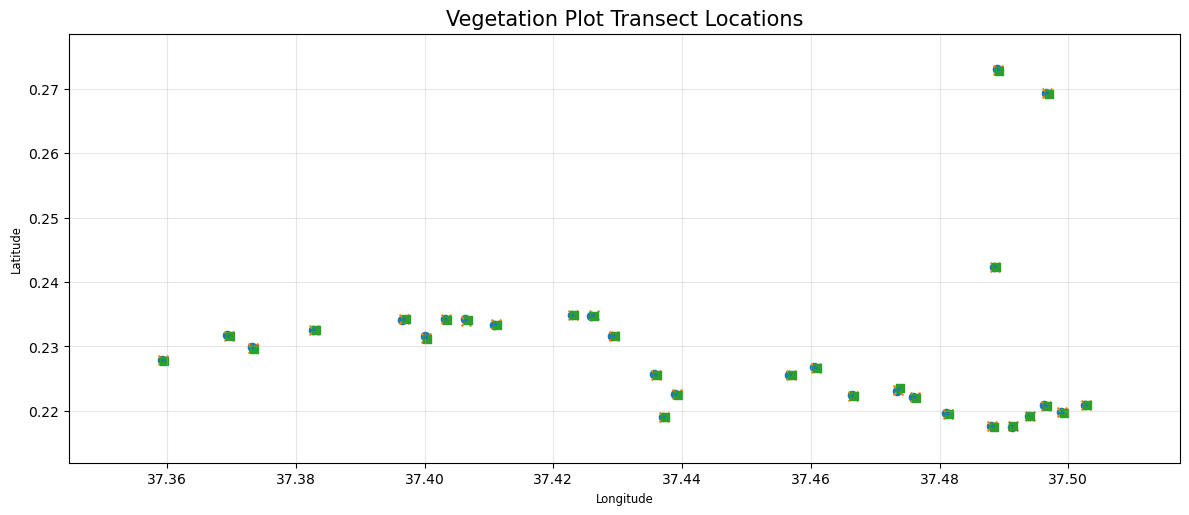

In [40]:
# Create a single spatial QC map of all vegetation transects from the `plots` dataframe by reconstructing each transect from its recorded Endpoint A, Midpoint, and Endpoint B coordinates, connecting the points in sequence (A → Midpoint → B), and overlaying all transect lines in one map frame. No plot names or labels are displayed on the individual transect lines so that the spatial pattern, orientation, spacing, and potential anomalies can be inspected clearly.

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point, LineString


# ============================================================
# 1. Extract transect coordinates
# ============================================================

transect = plots[[
    'plot_selection-plot_name',

    'plot_metadata-collect_points-endpoint_a-location_endpoint_a-Latitude',
    'plot_metadata-collect_points-endpoint_a-location_endpoint_a-Longitude',

    'plot_metadata-collect_points-midpoint-location_midpoint-Latitude',
    'plot_metadata-collect_points-midpoint-location_midpoint-Longitude',

    'plot_metadata-collect_points-endpoint_b-location_endpoint_b-Latitude',
    'plot_metadata-collect_points-endpoint_b-location_endpoint_b-Longitude'
]].copy()


# ============================================================
# 2. Rename columns
# ============================================================

transect.columns = [
    'plot_name',
    'a_lat', 'a_lon',
    'mid_lat', 'mid_lon',
    'b_lat', 'b_lon'
]


# ============================================================
# 3. Convert coordinates to numeric
# ============================================================

coord_cols = [
    'a_lat', 'a_lon',
    'mid_lat', 'mid_lon',
    'b_lat', 'b_lon'
]

transect[coord_cols] = transect[coord_cols].apply(
    pd.to_numeric,
    errors='coerce'
)


# ============================================================
# 4. Remove records with missing coordinates
# ============================================================

transect = transect.dropna(
    subset=coord_cols
).copy()


# ============================================================
# 5. Create transect lines
#    Endpoint A → Midpoint → Endpoint B
# ============================================================

transect['geometry'] = transect.apply(
    lambda row: LineString([
        (row['a_lon'], row['a_lat']),
        (row['mid_lon'], row['mid_lat']),
        (row['b_lon'], row['b_lat'])
    ]),
    axis=1
)


# ============================================================
# 6. Convert to GeoDataFrame
# ============================================================

transect_gdf = gpd.GeoDataFrame(
    transect,
    geometry='geometry',
    crs='EPSG:4326'
)


# ============================================================
# 7. Create ONE map frame
# ============================================================

fig, ax = plt.subplots(
    figsize=(12, 10)
)


# ============================================================
# 8. Plot ALL transect lines together
# ============================================================

transect_gdf.plot(
    ax=ax,
    linewidth=2
)


# ============================================================
# 9. Add Endpoint A
# ============================================================

endpoint_a = gpd.GeoDataFrame(
    transect,
    geometry=[
        Point(lon, lat)
        for lon, lat in zip(
            transect['a_lon'],
            transect['a_lat']
        )
    ],
    crs='EPSG:4326'
)

endpoint_a.plot(
    ax=ax,
    marker='o',
    markersize=35
)


# ============================================================
# 10. Add Midpoint
# ============================================================

midpoint = gpd.GeoDataFrame(
    transect,
    geometry=[
        Point(lon, lat)
        for lon, lat in zip(
            transect['mid_lon'],
            transect['mid_lat']
        )
    ],
    crs='EPSG:4326'
)

midpoint.plot(
    ax=ax,
    marker='x',
    markersize=50
)


# ============================================================
# 11. Add Endpoint B
# ============================================================

endpoint_b = gpd.GeoDataFrame(
    transect,
    geometry=[
        Point(lon, lat)
        for lon, lat in zip(
            transect['b_lon'],
            transect['b_lat']
        )
    ],
    crs='EPSG:4326'
)

endpoint_b.plot(
    ax=ax,
    marker='s',
    markersize=35
)


# ============================================================
# 12. Automatically fit map extent to ALL transects
# ============================================================

xmin, ymin, xmax, ymax = transect_gdf.total_bounds

x_buffer = (xmax - xmin) * 0.10
y_buffer = (ymax - ymin) * 0.10

ax.set_xlim(
    xmin - x_buffer,
    xmax + x_buffer
)

ax.set_ylim(
    ymin - y_buffer,
    ymax + y_buffer
)


# ============================================================
# 13. Map formatting
# ============================================================

ax.set_title(
    'Vegetation Plot Transect Locations',
    fontsize=15
)

ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

ax.grid(
    True,
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [41]:
# ============================================================
# 14. Create interactive Dash map with plot-level filter
# ============================================================

import dash
from dash import dcc, html
from dash.dependencies import Input, Output
import plotly.graph_objects as go


# ------------------------------------------------------------
# Create list of plots for the dropdown
# ------------------------------------------------------------

plot_options = [
    {'label': 'All plots', 'value': 'ALL'}
]

plot_options += [
    {'label': plot, 'value': plot}
    for plot in sorted(transect_gdf['plot_name'].unique())
]


# ------------------------------------------------------------
# Create Dash application
# ------------------------------------------------------------

app = dash.Dash(__name__)


# ------------------------------------------------------------
# Dashboard layout
# ------------------------------------------------------------

app.layout = html.Div([

    html.H2('Vegetation Plot Transect Spatial QC'),

    html.Label('Select Plot'),

    dcc.Dropdown(
        id='plot-filter',
        options=plot_options,
        value='ALL',
        clearable=False,
        style={'width': '400px'}
    ),

    dcc.Graph(
        id='transect-map',
        style={'height': '750px'}
    )

])


# ------------------------------------------------------------
# Update map when plot selection changes
# ------------------------------------------------------------

@app.callback(
    Output('transect-map', 'figure'),
    Input('plot-filter', 'value')
)
def update_map(selected_plot):

    # --------------------------------------------------------
    # Filter the GeoDataFrame
    # --------------------------------------------------------

    if selected_plot == 'ALL':

        filtered = transect_gdf.copy()

    else:

        filtered = transect_gdf[
            transect_gdf['plot_name'] == selected_plot
        ].copy()


    # --------------------------------------------------------
    # Create map
    # --------------------------------------------------------

    fig = go.Figure()


    # --------------------------------------------------------
    # Add transect lines
    # --------------------------------------------------------

    for _, row in filtered.iterrows():

        x, y = row.geometry.xy

        fig.add_trace(
            go.Scattermap(
                lon=list(x),
                lat=list(y),
                mode='lines',
                name=row['plot_name'],
                hovertemplate=(
                    '<b>%{text}</b><br>'
                    'Longitude: %{lon}<br>'
                    'Latitude: %{lat}'
                    '<extra></extra>'
                ),
                text=[row['plot_name']] * len(x)
            )
        )


    # --------------------------------------------------------
    # Add Endpoint A
    # --------------------------------------------------------

    fig.add_trace(
        go.Scattermap(
            lon=filtered['a_lon'],
            lat=filtered['a_lat'],
            mode='markers',
            marker={'size': 9},
            name='Endpoint A',
            hovertemplate=(
                '<b>Endpoint A</b><br>'
                'Longitude: %{lon}<br>'
                'Latitude: %{lat}'
                '<extra></extra>'
            )
        )
    )


    # --------------------------------------------------------
    # Add Midpoint
    # --------------------------------------------------------

    fig.add_trace(
        go.Scattermap(
            lon=filtered['mid_lon'],
            lat=filtered['mid_lat'],
            mode='markers',
            marker={'size': 10},
            name='Midpoint',
            hovertemplate=(
                '<b>Midpoint</b><br>'
                'Longitude: %{lon}<br>'
                'Latitude: %{lat}'
                '<extra></extra>'
            )
        )
    )


    # --------------------------------------------------------
    # Add Endpoint B
    # --------------------------------------------------------

    fig.add_trace(
        go.Scattermap(
            lon=filtered['b_lon'],
            lat=filtered['b_lat'],
            mode='markers',
            marker={'size': 9},
            name='Endpoint B',
            hovertemplate=(
                '<b>Endpoint B</b><br>'
                'Longitude: %{lon}<br>'
                'Latitude: %{lat}'
                '<extra></extra>'
            )
        )
    )


    # --------------------------------------------------------
    # Determine map centre
    # --------------------------------------------------------

    if len(filtered) > 0:

        centre_lat = (
            filtered['mid_lat'].mean()
        )

        centre_lon = (
            filtered['mid_lon'].mean()
        )

    else:

        centre_lat = 0
        centre_lon = 37


    # --------------------------------------------------------
    # Map formatting
    # --------------------------------------------------------

    fig.update_layout(

        map={
            'style': 'open-street-map',
            'center': {
                'lat': centre_lat,
                'lon': centre_lon
            },
            'zoom': 12
        },

        margin={
            'r': 10,
            't': 40,
            'l': 10,
            'b': 10
        },

        title='Vegetation Plot Transect Locations'

    )


    return fig


# ============================================================
# 15. Run Dash
# ============================================================

if __name__ == '__main__':

    app.run(
        debug=True
    )

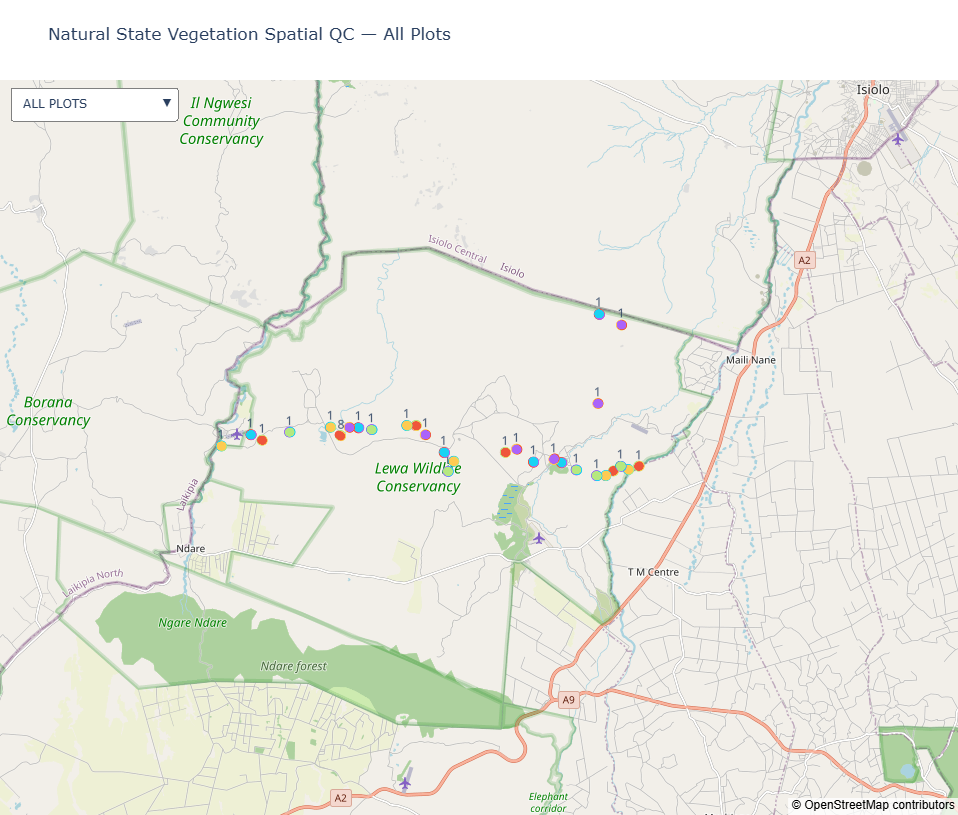

In [44]:
# ============================================================
# SPATIAL QC — INTERACTIVE PLOT MAP WITH DROPDOWN
# ============================================================

import pandas as pd
import geopandas as gpd
import plotly.graph_objects as go
from shapely.geometry import Point, LineString

# ============================================================
# 1. SETTINGS
# ============================================================

WGS84 = "EPSG:4326"
UTM = "EPSG:32737"

# Visualization/QC boundary width on each side of transect
BOUNDARY_HALF_WIDTH_M = 5

# ============================================================
# 2. EXACT COLUMN NAMES
# ============================================================

plot_name_col = "plot_selection-plot_name"

# Endpoint A
a_lat = "plot_metadata-collect_points-endpoint_a-location_endpoint_a-Latitude"
a_lon = "plot_metadata-collect_points-endpoint_a-location_endpoint_a-Longitude"
a_alt = "plot_metadata-collect_points-endpoint_a-location_endpoint_a-Altitude"

# Midpoint
m_lat = "plot_metadata-collect_points-midpoint-location_midpoint-Latitude"
m_lon = "plot_metadata-collect_points-midpoint-location_midpoint-Longitude"
m_alt = "plot_metadata-collect_points-midpoint-location_midpoint-Altitude"

# Endpoint B
b_lat = "plot_metadata-collect_points-endpoint_b-location_endpoint_b-Latitude"
b_lon = "plot_metadata-collect_points-endpoint_b-location_endpoint_b-Longitude"
b_alt = "plot_metadata-collect_points-endpoint_b-location_endpoint_b-Altitude"

# Quadrat GPS
q_lat = "location_quadrat-Latitude"
q_lon = "location_quadrat-Longitude"
q_alt = "location_quadrat-Altitude"
q_acc = "location_quadrat-Accuracy"
q_num = "quadrat_number"

# ============================================================
# 3. PREPARE PLOT REGISTRATION DATA
# ============================================================

plot_data = plots.copy()

coordinate_columns = [
    a_lat, a_lon, a_alt,
    m_lat, m_lon, m_alt,
    b_lat, b_lon, b_alt
]

for col in coordinate_columns:
    plot_data[col] = pd.to_numeric(
        plot_data[col],
        errors="coerce"
    )

plot_data[plot_name_col] = (
    plot_data[plot_name_col]
    .astype(str)
    .str.strip()
)

# ============================================================
# 4. PREPARE QUADRAT DATA
# ============================================================

quadrat_qc = survey_quadrat.copy()

for col in [q_lat, q_lon, q_alt, q_acc]:
    quadrat_qc[col] = pd.to_numeric(
        quadrat_qc[col],
        errors="coerce"
    )

# Link quadrats to plot name
quadrat_qc["plot_name"] = (
    quadrat_qc[plot_name_col]
    .astype(str)
    .str.strip()
)

# ============================================================
# 5. BUILD TRANSECTS
# ============================================================

transects = []

for _, row in plot_data.iterrows():

    plot_name = row[plot_name_col]

    # --------------------------------------------------------
    # Validate Endpoint A and B
    # --------------------------------------------------------

    if (
        pd.isna(row[a_lat]) or
        pd.isna(row[a_lon]) or
        pd.isna(row[b_lat]) or
        pd.isna(row[b_lon])
    ):
        continue

    # Geographic sanity check
    if not (
        -90 <= row[a_lat] <= 90 and
        -180 <= row[a_lon] <= 180 and
        -90 <= row[b_lat] <= 90 and
        -180 <= row[b_lon] <= 180
    ):
        continue

    # --------------------------------------------------------
    # Create transect
    # --------------------------------------------------------

    line_wgs84 = LineString([
        (row[a_lon], row[a_lat]),
        (row[b_lon], row[b_lat])
    ])

    # Reject invalid / zero-length transects
    if line_wgs84.is_empty or line_wgs84.length == 0:
        continue

    # --------------------------------------------------------
    # Convert to UTM for metric calculations
    # --------------------------------------------------------

    line_gdf = gpd.GeoDataFrame(
        {"geometry": [line_wgs84]},
        crs=WGS84
    )

    line_metric = line_gdf.to_crs(UTM).geometry.iloc[0]

    # --------------------------------------------------------
    # Calculated midpoint
    # --------------------------------------------------------

    calculated_midpoint = line_metric.interpolate(
        line_metric.length / 2
    )

    calculated_midpoint_wgs84 = (
        gpd.GeoSeries(
            [calculated_midpoint],
            crs=UTM
        )
        .to_crs(WGS84)
        .iloc[0]
    )

    calculated_midpoint_lat = calculated_midpoint_wgs84.y
    calculated_midpoint_lon = calculated_midpoint_wgs84.x

    # --------------------------------------------------------
    # Recorded midpoint
    # --------------------------------------------------------

    midpoint_valid = (
        pd.notna(row[m_lat]) and
        pd.notna(row[m_lon]) and
        -90 <= row[m_lat] <= 90 and
        -180 <= row[m_lon] <= 180
    )

    recorded_vs_calculated_midpoint_m = None

    if midpoint_valid:

        recorded_midpoint = Point(
            row[m_lon],
            row[m_lat]
        )

        recorded_midpoint_metric = (
            gpd.GeoSeries(
                [recorded_midpoint],
                crs=WGS84
            )
            .to_crs(UTM)
            .iloc[0]
        )

        recorded_vs_calculated_midpoint_m = round(
            recorded_midpoint_metric.distance(
                calculated_midpoint
            ),
            3
        )

    # --------------------------------------------------------
    # Boundary around transect
    # --------------------------------------------------------

    boundary_metric = line_metric.buffer(
        BOUNDARY_HALF_WIDTH_M,
        cap_style=2
    )

    boundary_wgs84 = (
        gpd.GeoSeries(
            [boundary_metric],
            crs=UTM
        )
        .to_crs(WGS84)
        .iloc[0]
    )

    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    transects.append({

        "plot_name": plot_name,

        "a_lat": row[a_lat],
        "a_lon": row[a_lon],
        "a_alt": row[a_alt],

        "m_lat": row[m_lat],
        "m_lon": row[m_lon],
        "m_alt": row[m_alt],

        "b_lat": row[b_lat],
        "b_lon": row[b_lon],
        "b_alt": row[b_alt],

        "line_wgs84": line_wgs84,
        "line_metric": line_metric,

        "boundary_wgs84": boundary_wgs84,
        "boundary_metric": boundary_metric,

        "calculated_midpoint_lat":
            calculated_midpoint_lat,

        "calculated_midpoint_lon":
            calculated_midpoint_lon,

        "calculated_midpoint_metric":
            calculated_midpoint,

        "midpoint_valid":
            midpoint_valid,

        "recorded_vs_calculated_midpoint_m":
            recorded_vs_calculated_midpoint_m
    })


# ============================================================
# 6. QUADRAT SPATIAL QC
# ============================================================

quadrat_records = []

for t in transects:

    plot_name = t["plot_name"]

    q = quadrat_qc[
        quadrat_qc["plot_name"] == plot_name
    ].copy()

    if q.empty:
        continue

    # Keep only valid coordinates
    q = q[
        q[q_lat].notna() &
        q[q_lon].notna()
    ].copy()

    if q.empty:
        continue

    # --------------------------------------------------------
    # Convert quadrats to GeoDataFrame
    # --------------------------------------------------------

    q_gdf = gpd.GeoDataFrame(
        q,
        geometry=[
            Point(lon, lat)
            for lon, lat
            in zip(q[q_lon], q[q_lat])
        ],
        crs=WGS84
    )

    q_metric = q_gdf.to_crs(UTM)

    # --------------------------------------------------------
    # Calculate QC
    # --------------------------------------------------------

    for idx, qrow in q_metric.iterrows():

        point = qrow.geometry

        distance_to_transect = point.distance(
            t["line_metric"]
        )

        distance_to_recorded_midpoint = None

        if t["midpoint_valid"]:

            recorded_midpoint = Point(
                t["m_lon"],
                t["m_lat"]
            )

            recorded_midpoint_metric = (
                gpd.GeoSeries(
                    [recorded_midpoint],
                    crs=WGS84
                )
                .to_crs(UTM)
                .iloc[0]
            )

            distance_to_recorded_midpoint = (
                point.distance(
                    recorded_midpoint_metric
                )
            )

        distance_to_calculated_midpoint = point.distance(
            t["calculated_midpoint_metric"]
        )

        inside_boundary = (
            point.within(t["boundary_metric"])
        )

        spatial_qc = (
            "PASS"
            if inside_boundary
            else "FAIL"
        )

        quadrat_records.append({

            "plot_name": plot_name,

            "quadrat_number":
                qrow[q_num],

            "latitude":
                qrow[q_lat],

            "longitude":
                qrow[q_lon],

            "altitude":
                qrow[q_alt],

            "accuracy":
                qrow[q_acc],

            "distance_to_transect_m":
                round(distance_to_transect, 3),

            "distance_to_recorded_midpoint_m":
                (
                    round(
                        distance_to_recorded_midpoint,
                        3
                    )
                    if distance_to_recorded_midpoint
                    is not None
                    else None
                ),

            "distance_to_calculated_midpoint_m":
                round(
                    distance_to_calculated_midpoint,
                    3
                ),

            "inside_boundary":
                inside_boundary,

            "spatial_qc":
                spatial_qc
        })


# ============================================================
# 7. CREATE QUADRAT QC DATAFRAME
# ============================================================

if quadrat_records:

    quadrat_qc_map = pd.DataFrame(
        quadrat_records
    )

else:

    quadrat_qc_map = pd.DataFrame(
        columns=[
            "plot_name",
            "quadrat_number",
            "latitude",
            "longitude",
            "altitude",
            "accuracy",
            "distance_to_transect_m",
            "distance_to_recorded_midpoint_m",
            "distance_to_calculated_midpoint_m",
            "inside_boundary",
            "spatial_qc"
        ]
    )


# ============================================================
# 8. CREATE FIGURE
# ============================================================

fig = go.Figure()

trace_groups = {}

# ============================================================
# 9. ADD EACH PLOT
# ============================================================

for t in transects:

    plot_name = t["plot_name"]

    start_trace = len(fig.data)

    # ========================================================
    # 9A. TRANSECT BOUNDARY
    # ========================================================

    boundary_coords = list(
        t["boundary_wgs84"].exterior.coords
    )

    fig.add_trace(

        go.Scattermap(

            lat=[
                p[1]
                for p in boundary_coords
            ],

            lon=[
                p[0]
                for p in boundary_coords
            ],

            mode="lines",

            name="Transect boundary",

            line=dict(
                width=1
            ),

            hovertemplate=(
                f"<b>{plot_name}</b><br>"
                "Transect boundary"
                "<extra></extra>"
            ),

            visible=True
        )
    )

    # ========================================================
    # 9B. TRANSECT LINE
    # ========================================================

    fig.add_trace(

        go.Scattermap(

            lat=[
                t["a_lat"],
                t["b_lat"]
            ],

            lon=[
                t["a_lon"],
                t["b_lon"]
            ],

            mode="lines",

            name="Transect",

            line=dict(
                width=3
            ),

            hovertemplate=(
                f"<b>{plot_name}</b><br>"
                "Endpoint A → Endpoint B"
                "<extra></extra>"
            ),

            visible=True
        )
    )

    # ========================================================
    # 9C. ENDPOINT A
    # ========================================================

    fig.add_trace(

        go.Scattermap(

            lat=[t["a_lat"]],
            lon=[t["a_lon"]],

            mode="markers",

            name="Endpoint A",

            marker=dict(
                size=11
            ),

            hovertemplate=(
                f"<b>{plot_name}</b><br>"
                "Endpoint A<br>"
                f"Latitude: {t['a_lat']:.7f}<br>"
                f"Longitude: {t['a_lon']:.7f}<br>"
                f"Altitude: {t['a_alt']} m"
                "<extra></extra>"
            ),

            visible=True
        )
    )

    # ========================================================
    # 9D. RECORDED MIDPOINT
    # ========================================================

    if t["midpoint_valid"]:

        fig.add_trace(

            go.Scattermap(

                lat=[t["m_lat"]],
                lon=[t["m_lon"]],

                mode="markers",

                name="Recorded midpoint",

                marker=dict(
                    size=12
                ),

                hovertemplate=(
                    f"<b>{plot_name}</b><br>"
                    "Recorded midpoint<br>"
                    f"Latitude: {t['m_lat']:.7f}<br>"
                    f"Longitude: {t['m_lon']:.7f}<br>"
                    f"Altitude: {t['m_alt']} m<br>"
                    f"Difference from calculated: "
                    f"{t['recorded_vs_calculated_midpoint_m']} m"
                    "<extra></extra>"
                ),

                visible=True
            )
        )

    # ========================================================
    # 9E. CALCULATED MIDPOINT
    # ========================================================

    fig.add_trace(

        go.Scattermap(

            lat=[
                t["calculated_midpoint_lat"]
            ],

            lon=[
                t["calculated_midpoint_lon"]
            ],

            mode="markers",

            name="Calculated midpoint",

            marker=dict(
                size=10
            ),

            hovertemplate=(
                f"<b>{plot_name}</b><br>"
                "Calculated midpoint<br>"
                f"Latitude: "
                f"{t['calculated_midpoint_lat']:.7f}<br>"
                f"Longitude: "
                f"{t['calculated_midpoint_lon']:.7f}<br>"
                f"Recorded vs calculated difference: "
                f"{t['recorded_vs_calculated_midpoint_m']} m"
                "<extra></extra>"
            ),

            visible=True
        )
    )

    # ========================================================
    # 9F. ENDPOINT B
    # ========================================================

    fig.add_trace(

        go.Scattermap(

            lat=[t["b_lat"]],
            lon=[t["b_lon"]],

            mode="markers",

            name="Endpoint B",

            marker=dict(
                size=11
            ),

            hovertemplate=(
                f"<b>{plot_name}</b><br>"
                "Endpoint B<br>"
                f"Latitude: {t['b_lat']:.7f}<br>"
                f"Longitude: {t['b_lon']:.7f}<br>"
                f"Altitude: {t['b_alt']} m"
                "<extra></extra>"
            ),

            visible=True
        )
    )

    # ========================================================
    # 9G. MIDPOINT DIFFERENCE LINE
    # ========================================================

    if t["midpoint_valid"]:

        fig.add_trace(

            go.Scattermap(

                lat=[
                    t["m_lat"],
                    t["calculated_midpoint_lat"]
                ],

                lon=[
                    t["m_lon"],
                    t["calculated_midpoint_lon"]
                ],

                mode="lines",

                name="Midpoint difference",

                # IMPORTANT:
                # Scattermap does NOT support dash.
                line=dict(
                    width=2
                ),

                hovertemplate=(
                    f"<b>{plot_name}</b><br>"
                    "Recorded midpoint → "
                    "calculated midpoint<br>"
                    f"Difference: "
                    f"{t['recorded_vs_calculated_midpoint_m']} m"
                    "<extra></extra>"
                ),

                visible=True
            )
        )

    # ========================================================
    # 9H. QUADRAT GPS POINTS
    # ========================================================

    q = quadrat_qc_map[
        quadrat_qc_map["plot_name"] == plot_name
    ].copy()

    if not q.empty:

        hover_text = []

        for _, qr in q.iterrows():

            hover_text.append(

                f"<b>{plot_name}</b><br>"
                f"Quadrat: {qr['quadrat_number']}<br>"
                f"Latitude: {qr['latitude']:.7f}<br>"
                f"Longitude: {qr['longitude']:.7f}<br>"
                f"Altitude: {qr['altitude']} m<br>"
                f"GPS accuracy: {qr['accuracy']} m<br>"
                f"Distance to transect: "
                f"{qr['distance_to_transect_m']} m<br>"
                f"Distance to recorded midpoint: "
                f"{qr['distance_to_recorded_midpoint_m']} m<br>"
                f"Distance to calculated midpoint: "
                f"{qr['distance_to_calculated_midpoint_m']} m<br>"
                f"Inside boundary: "
                f"{qr['inside_boundary']}<br>"
                f"<b>Spatial QC: {qr['spatial_qc']}</b>"
                "<extra></extra>"
            )

        fig.add_trace(

            go.Scattermap(

                lat=q["latitude"].tolist(),

                lon=q["longitude"].tolist(),

                mode="markers+text",

                text=[
                    str(x)
                    for x in q["quadrat_number"]
                ],

                textposition="top center",

                name="Quadrat GPS",

                marker=dict(
                    size=9
                ),

                hovertemplate=hover_text,

                visible=True
            )
        )

    # ========================================================
    # STORE TRACE RANGE
    # ========================================================

    end_trace = len(fig.data) - 1

    trace_groups[plot_name] = (
        start_trace,
        end_trace
    )


# ============================================================
# 10. DROPDOWN
# ============================================================

plot_names = list(trace_groups.keys())

buttons = []

# ------------------------------------------------------------
# ALL PLOTS
# ------------------------------------------------------------

buttons.append(

    dict(

        label="ALL PLOTS",

        method="update",

        args=[
            {
                "visible": [
                    True
                    for _ in fig.data
                ]
            },
            {
                "title": {
                    "text":
                    "Natural State Vegetation Spatial QC — All Plots"
                }
            }
        ]
    )
)


# ------------------------------------------------------------
# INDIVIDUAL PLOTS
# ------------------------------------------------------------

for selected_plot in plot_names:

    visible = [
        False
        for _ in fig.data
    ]

    start, end = trace_groups[selected_plot]

    for i in range(start, end + 1):
        visible[i] = True

    buttons.append(

        dict(

            label=selected_plot,

            method="update",

            args=[
                {
                    "visible": visible
                },
                {
                    "title": {
                        "text":
                        f"Natural State Vegetation Spatial QC — {selected_plot}"
                    }
                }
            ]
        )
    )


# ============================================================
# 11. MAP LAYOUT
# ============================================================

fig.update_layout(

    title={
        "text":
        "Natural State Vegetation Spatial QC — All Plots"
    },

    map=dict(

        style="open-street-map",

        center=dict(

            lat=float(
                plot_data[a_lat].median()
            ),

            lon=float(
                plot_data[a_lon].median()
            )
        ),

        zoom=11
    ),

    height=800,

    margin=dict(
        l=0,
        r=0,
        t=80,
        b=0
    ),

    updatemenus=[

        dict(

            type="dropdown",

            direction="down",

            buttons=buttons,

            x=0.01,

            xanchor="left",

            y=0.99,

            yanchor="top",

            bgcolor="white",

            bordercolor="gray",

            borderwidth=1,

            font=dict(
                size=12
            )
        )
    ],

    showlegend=False
)


# ============================================================
# 12. DISPLAY MAP ONLY
# ============================================================

fig.show()

In [45]:
survey_quadrat = survey_quadrat.merge(
    vegplots,
    left_on='plot_selection-selected_plot_uuid',
    right_on='__id',
    how='left'
)

In [46]:
# Remove previous merge columns
survey_quadrat = survey_quadrat.drop(
    columns=['__id', 'geohash', 'plot_name', '_merge'],
    errors='ignore'
)

# Merge again
survey_quadrat = survey_quadrat.merge(
    vegplots[['__id', 'geohash', 'plot_name']],
    left_on='plot_selection-selected_plot_uuid',
    right_on='__id',
    how='left',
    indicator=True
)

# Check how the merge worked
print(survey_quadrat['_merge'].value_counts())

_merge
both          640
left_only       0
right_only      0
Name: count, dtype: int64


In [47]:
import pygeohash as pgh

survey_quadrat['quadrat_geohash'] = survey_quadrat.apply(
    lambda x: pgh.encode(
        x['location_quadrat-Latitude'],
        x['location_quadrat-Longitude'],
        precision=len(str(survey_quadrat['geohash'].dropna().iloc[0]))
    ),
    axis=1
)

survey_quadrat['geohash_match'] = (
    survey_quadrat['quadrat_geohash'] == survey_quadrat['geohash']
)

In [48]:
survey_quadrat


,SubmissionDate,note_overview,field_team_specifics-selected_transport_type_uuid,field_team_specifics-transport_type_label,field_team_specifics-selected_project_team_uuid_multi,field_team_specifics-recorder_uuid,field_team_specifics-recorder_label,survey_begin-start_time,survey_begin-survey_year,survey_begin-selected_survey_uuid,...,__creatorName_y,__updates_y,__updatedAt_y,__version_y,__id,geohash,plot_name,_merge,quadrat_geohash,geohash_match
0,2026-05-27T08:46:04.721Z,NaN,8f2c4e19-bf36-4482-a15b-1464fa64ee6b,Vehicle,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-...,32c9ea24-1a8d-41d6-8f2e-4a94b08ffacc,Grace,2026-05-27T09:41:43.843+02:00,2026,858076d3-1f5a-4aad-b9ad-1205828807e0,...,field-team-2,0,NaN,1,b1e1fc7f-afbd-404c-bd6c-55b172d722df,sb49hzv,SavMon_LW_Plot_16,both,sb49hzu,False
1,2026-05-27T08:46:04.721Z,NaN,8f2c4e19-bf36-4482-a15b-1464fa64ee6b,Vehicle,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-...,32c9ea24-1a8d-41d6-8f2e-4a94b08ffacc,Grace,2026-05-27T09:41:43.843+02:00,2026,858076d3-1f5a-4aad-b9ad-1205828807e0,...,field-team-2,0,NaN,1,b1e1fc7f-afbd-404c-bd6c-55b172d722df,sb49hzv,SavMon_LW_Plot_16,both,sb49hzu,False
2,2026-05-27T08:46:04.721Z,NaN,8f2c4e19-bf36-4482-a15b-1464fa64ee6b,Vehicle,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-...,32c9ea24-1a8d-41d6-8f2e-4a94b08ffacc,Grace,2026-05-27T09:41:43.843+02:00,2026,858076d3-1f5a-4aad-b9ad-1205828807e0,...,field-team-2,0,NaN,1,b1e1fc7f-afbd-404c-bd6c-55b172d722df,sb49hzv,SavMon_LW_Plot_16,both,sb49hzu,False
3,2026-05-27T08:46:04.721Z,NaN,8f2c4e19-bf36-4482-a15b-1464fa64ee6b,Vehicle,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-...,32c9ea24-1a8d-41d6-8f2e-4a94b08ffacc,Grace,2026-05-27T09:41:43.843+02:00,2026,858076d3-1f5a-4aad-b9ad-1205828807e0,...,field-team-2,0,NaN,1,b1e1fc7f-afbd-404c-bd6c-55b172d722df,sb49hzv,SavMon_LW_Plot_16,both,sb49hzu,False
4,2026-05-27T08:46:04.721Z,NaN,8f2c4e19-bf36-4482-a15b-1464fa64ee6b,Vehicle,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-...,32c9ea24-1a8d-41d6-8f2e-4a94b08ffacc,Grace,2026-05-27T09:41:43.843+02:00,2026,858076d3-1f5a-4aad-b9ad-1205828807e0,...,field-team-2,0,NaN,1,b1e1fc7f-afbd-404c-bd6c-55b172d722df,sb49hzv,SavMon_LW_Plot_16,both,sb49hzu,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
635,2026-05-19T16:39:57.981Z,NaN,8f2c4e19-bf36-4482-a15b-1464fa64ee6b,Vehicle,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-...,3d8e9574-9d4d-4af3-90dd-bd381203f80a,Sam,2026-05-19T10:42:21.229+02:00,2026,858076d3-1f5a-4aad-b9ad-1205828807e0,...,field-team-1,0,NaN,1,edf62d32-bf13-47ec-ad1c-356bed17570a,sb4961k,SavMon_LW_Plot_08,both,sb4961k,True
636,2026-05-19T16:39:57.981Z,NaN,8f2c4e19-bf36-4482-a15b-1464fa64ee6b,Vehicle,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-...,3d8e9574-9d4d-4af3-90dd-bd381203f80a,Sam,2026-05-19T10:42:21.229+02:00,2026,858076d3-1f5a-4aad-b9ad-1205828807e0,...,field-team-1,0,NaN,1,edf62d32-bf13-47ec-ad1c-356bed17570a,sb4961k,SavMon_LW_Plot_08,both,sb4961k,True
637,2026-05-19T16:39:57.981Z,NaN,8f2c4e19-bf36-4482-a15b-1464fa64ee6b,Vehicle,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-...,3d8e9574-9d4d-4af3-90dd-bd381203f80a,Sam,2026-05-19T10:42:21.229+02:00,2026,858076d3-1f5a-4aad-b9ad-1205828807e0,...,field-team-1,0,NaN,1,edf62d32-bf13-47ec-ad1c-356bed17570a,sb4961k,SavMon_LW_Plot_08,both,sb4961k,True
638,2026-05-19T16:39:57.981Z,NaN,8f2c4e19-bf36-4482-a15b-1464fa64ee6b,Vehicle,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-...,3d8e9574-9d4d-4af3-90dd-bd381203f80a,Sam,2026-05-19T10:42:21.229+02:00,2026,858076d3-1f5a-4aad-b9ad-1205828807e0,...,field-team-1,0,NaN,1,edf62d32-bf13-47ec-ad1c-356bed17570a,sb4961k,SavMon_LW_Plot_08,both,sb4961k,True


In [49]:
summary_table = (
    survey_quadrat
    .groupby('plot_name')
    .agg(
        quadrants_within=('geohash_match', 'sum'),
        quadrants_outside=('geohash_match', lambda x: (~x).sum()),
        total_quadrants=('geohash_match', 'count')
    )
    .reset_index()
)

summary_table

,plot_name,quadrants_within,quadrants_outside,total_quadrants
0,SavMon_LW_Plot_01,10,10,20
1,SavMon_LW_Plot_02,20,0,20
2,SavMon_LW_Plot_03,20,0,20
3,SavMon_LW_Plot_04,10,10,20
4,SavMon_LW_Plot_05,20,0,20
5,SavMon_LW_Plot_06,20,0,20
6,SavMon_LW_Plot_07,20,0,20
7,SavMon_LW_Plot_08,20,0,20
8,SavMon_LW_Plot_09,20,0,20
9,SavMon_LW_Plot_10,11,9,20


In [50]:
survey_quadrat

,SubmissionDate,note_overview,field_team_specifics-selected_transport_type_uuid,field_team_specifics-transport_type_label,field_team_specifics-selected_project_team_uuid_multi,field_team_specifics-recorder_uuid,field_team_specifics-recorder_label,survey_begin-start_time,survey_begin-survey_year,survey_begin-selected_survey_uuid,...,__creatorName_y,__updates_y,__updatedAt_y,__version_y,__id,geohash,plot_name,_merge,quadrat_geohash,geohash_match
0,2026-05-27T08:46:04.721Z,NaN,8f2c4e19-bf36-4482-a15b-1464fa64ee6b,Vehicle,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-...,32c9ea24-1a8d-41d6-8f2e-4a94b08ffacc,Grace,2026-05-27T09:41:43.843+02:00,2026,858076d3-1f5a-4aad-b9ad-1205828807e0,...,field-team-2,0,NaN,1,b1e1fc7f-afbd-404c-bd6c-55b172d722df,sb49hzv,SavMon_LW_Plot_16,both,sb49hzu,False
1,2026-05-27T08:46:04.721Z,NaN,8f2c4e19-bf36-4482-a15b-1464fa64ee6b,Vehicle,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-...,32c9ea24-1a8d-41d6-8f2e-4a94b08ffacc,Grace,2026-05-27T09:41:43.843+02:00,2026,858076d3-1f5a-4aad-b9ad-1205828807e0,...,field-team-2,0,NaN,1,b1e1fc7f-afbd-404c-bd6c-55b172d722df,sb49hzv,SavMon_LW_Plot_16,both,sb49hzu,False
2,2026-05-27T08:46:04.721Z,NaN,8f2c4e19-bf36-4482-a15b-1464fa64ee6b,Vehicle,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-...,32c9ea24-1a8d-41d6-8f2e-4a94b08ffacc,Grace,2026-05-27T09:41:43.843+02:00,2026,858076d3-1f5a-4aad-b9ad-1205828807e0,...,field-team-2,0,NaN,1,b1e1fc7f-afbd-404c-bd6c-55b172d722df,sb49hzv,SavMon_LW_Plot_16,both,sb49hzu,False
3,2026-05-27T08:46:04.721Z,NaN,8f2c4e19-bf36-4482-a15b-1464fa64ee6b,Vehicle,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-...,32c9ea24-1a8d-41d6-8f2e-4a94b08ffacc,Grace,2026-05-27T09:41:43.843+02:00,2026,858076d3-1f5a-4aad-b9ad-1205828807e0,...,field-team-2,0,NaN,1,b1e1fc7f-afbd-404c-bd6c-55b172d722df,sb49hzv,SavMon_LW_Plot_16,both,sb49hzu,False
4,2026-05-27T08:46:04.721Z,NaN,8f2c4e19-bf36-4482-a15b-1464fa64ee6b,Vehicle,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-...,32c9ea24-1a8d-41d6-8f2e-4a94b08ffacc,Grace,2026-05-27T09:41:43.843+02:00,2026,858076d3-1f5a-4aad-b9ad-1205828807e0,...,field-team-2,0,NaN,1,b1e1fc7f-afbd-404c-bd6c-55b172d722df,sb49hzv,SavMon_LW_Plot_16,both,sb49hzu,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
635,2026-05-19T16:39:57.981Z,NaN,8f2c4e19-bf36-4482-a15b-1464fa64ee6b,Vehicle,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-...,3d8e9574-9d4d-4af3-90dd-bd381203f80a,Sam,2026-05-19T10:42:21.229+02:00,2026,858076d3-1f5a-4aad-b9ad-1205828807e0,...,field-team-1,0,NaN,1,edf62d32-bf13-47ec-ad1c-356bed17570a,sb4961k,SavMon_LW_Plot_08,both,sb4961k,True
636,2026-05-19T16:39:57.981Z,NaN,8f2c4e19-bf36-4482-a15b-1464fa64ee6b,Vehicle,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-...,3d8e9574-9d4d-4af3-90dd-bd381203f80a,Sam,2026-05-19T10:42:21.229+02:00,2026,858076d3-1f5a-4aad-b9ad-1205828807e0,...,field-team-1,0,NaN,1,edf62d32-bf13-47ec-ad1c-356bed17570a,sb4961k,SavMon_LW_Plot_08,both,sb4961k,True
637,2026-05-19T16:39:57.981Z,NaN,8f2c4e19-bf36-4482-a15b-1464fa64ee6b,Vehicle,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-...,3d8e9574-9d4d-4af3-90dd-bd381203f80a,Sam,2026-05-19T10:42:21.229+02:00,2026,858076d3-1f5a-4aad-b9ad-1205828807e0,...,field-team-1,0,NaN,1,edf62d32-bf13-47ec-ad1c-356bed17570a,sb4961k,SavMon_LW_Plot_08,both,sb4961k,True
638,2026-05-19T16:39:57.981Z,NaN,8f2c4e19-bf36-4482-a15b-1464fa64ee6b,Vehicle,3d8e9574-9d4d-4af3-90dd-bd381203f80a 69eaf9dd-...,3d8e9574-9d4d-4af3-90dd-bd381203f80a,Sam,2026-05-19T10:42:21.229+02:00,2026,858076d3-1f5a-4aad-b9ad-1205828807e0,...,field-team-1,0,NaN,1,edf62d32-bf13-47ec-ad1c-356bed17570a,sb4961k,SavMon_LW_Plot_08,both,sb4961k,True


In [51]:
import pygeohash as pgh
import pandas as pd
import plotly.graph_objects as go

from shapely.geometry import Polygon
from dash import Dash, dcc, html, Input, Output

print("Imports successful")

Imports successful


In [52]:
# ============================================================
# DASH SPATIAL QC — PRESCRIBED GEOHASH + QUADRAT GPS
# ============================================================

import pygeohash as pgh
import pandas as pd

from shapely.geometry import Polygon
import plotly.graph_objects as go

from dash import Dash, dcc, html, Input, Output


# ============================================================
# 1. FUNCTION TO CREATE GEOHASH POLYGON
# ============================================================

def geohash_polygon(geohash):

    lat, lon, lat_err, lon_err = pgh.decode_exactly(geohash)

    return Polygon([
        (lon - lon_err, lat - lat_err),
        (lon - lon_err, lat + lat_err),
        (lon + lon_err, lat + lat_err),
        (lon + lon_err, lat - lat_err)
    ])


# ============================================================
# 2. CLEAN DATA USED BY THE DASHBOARD
# ============================================================

map_data = survey_quadrat[
    [
        'plot_name',
        'geohash',
        'quadrat_geohash',
        'geohash_match',
        'location_quadrat-Latitude',
        'location_quadrat-Longitude',
        'quadrat_number'
    ]
].copy()


# Remove records without GPS coordinates
map_data = map_data.dropna(
    subset=[
        'location_quadrat-Latitude',
        'location_quadrat-Longitude'
    ]
)


# ============================================================
# 3. LIST OF PLOTS
# ============================================================

plot_options = sorted(
    map_data['plot_name'].dropna().unique()
)


# ============================================================
# 4. CREATE DASH APP
# ============================================================

app = Dash(__name__)


app.layout = html.Div([

    html.H2(
        "Natural State — Quadrat Spatial QA/QC"
    ),

    html.Label(
        "Select plot:"
    ),

    dcc.Dropdown(
        id='plot-dropdown',
        options=[
            {
                'label': plot,
                'value': plot
            }
            for plot in plot_options
        ],
        value=plot_options[0],
        clearable=False,
        style={
            'width': '400px',
            'marginBottom': '20px'
        }
    ),

    dcc.Graph(
        id='spatial-qc-map',
        style={
            'height': '750px'
        }
    )

])


# ============================================================
# 5. MAP CALLBACK
# ============================================================

@app.callback(
    Output('spatial-qc-map', 'figure'),
    Input('plot-dropdown', 'value')
)
def update_map(selected_plot):

    # --------------------------------------------------------
    # Filter selected plot
    # --------------------------------------------------------

    df = map_data[
        map_data['plot_name'] == selected_plot
    ].copy()


    # --------------------------------------------------------
    # Get prescribed geohash
    # --------------------------------------------------------

    prescribed_geohash = df['geohash'].dropna().iloc[0]


    # --------------------------------------------------------
    # Create prescribed geohash polygon
    # --------------------------------------------------------

    polygon = geohash_polygon(
        prescribed_geohash
    )

    polygon_lon, polygon_lat = polygon.exterior.xy


    # --------------------------------------------------------
    # Create figure
    # --------------------------------------------------------

    fig = go.Figure()


    # ========================================================
    # 6. ADD PRESCRIBED GEOHASH CELL
    # ========================================================

    fig.add_trace(
        go.Scattermap(
            lon=list(polygon_lon),
            lat=list(polygon_lat),
            mode='lines',
            name='Prescribed geohash',
            line=dict(
                width=3
            ),
            hoverinfo='text',
            text=[
                f"Prescribed geohash: {prescribed_geohash}"
            ] * len(polygon_lon)
        )
    )


    # Close the polygon visually
    fig.add_trace(
        go.Scattermap(
            lon=list(polygon_lon),
            lat=list(polygon_lat),
            mode='lines',
            name='Geohash boundary',
            showlegend=False,
            line=dict(
                width=3
            )
        )
    )


    # ========================================================
    # 7. QUADRATS WITHIN PRESCRIBED GEOHASH
    # ========================================================

    within = df[
        df['geohash_match'] == True
    ]


    if len(within) > 0:

        fig.add_trace(
            go.Scattermap(
                lon=within[
                    'location_quadrat-Longitude'
                ],
                lat=within[
                    'location_quadrat-Latitude'
                ],
                mode='markers',
                name='Quadrat within geohash',

                marker=dict(
                    size=10
                ),

                text=within[
                    'quadrat_number'
                ],

                hovertemplate=
                    '<b>Quadrat %{text}</b><br>' +
                    'Latitude: %{lat:.6f}<br>' +
                    'Longitude: %{lon:.6f}<br>' +
                    'Geohash: ' +
                    within['quadrat_geohash'].astype(str) +
                    '<br>Status: WITHIN' +
                    '<extra></extra>'
            )
        )


    # ========================================================
    # 8. QUADRATS OUTSIDE PRESCRIBED GEOHASH
    # ========================================================

    outside = df[
        df['geohash_match'] == False
    ]


    if len(outside) > 0:

        fig.add_trace(
            go.Scattermap(
                lon=outside[
                    'location_quadrat-Longitude'
                ],
                lat=outside[
                    'location_quadrat-Latitude'
                ],
                mode='markers',
                name='Quadrat outside geohash',

                marker=dict(
                    size=12
                ),

                text=outside[
                    'quadrat_number'
                ],

                hovertemplate=
                    '<b>Quadrat %{text}</b><br>' +
                    'Latitude: %{lat:.6f}<br>' +
                    'Longitude: %{lon:.6f}<br>' +
                    'Geohash: ' +
                    outside['quadrat_geohash'].astype(str) +
                    '<br>Status: OUTSIDE' +
                    '<extra></extra>'
            )
        )


    # ========================================================
    # 9. MAP EXTENT
    # ========================================================

    all_lat = list(
        df['location_quadrat-Latitude']
    ) + list(polygon_lat)

    all_lon = list(
        df['location_quadrat-Longitude']
    ) + list(polygon_lon)


    center_lat = sum(all_lat) / len(all_lat)
    center_lon = sum(all_lon) / len(all_lon)


    # ========================================================
    # 10. MAP LAYOUT
    # ========================================================

    fig.update_layout(

        title=(
            f"Plot: {selected_plot} | "
            f"Prescribed geohash: {prescribed_geohash}"
        ),

        map=dict(
            style="open-street-map",
            center=dict(
                lat=center_lat,
                lon=center_lon
            ),
            zoom=17
        ),

        margin=dict(
            l=10,
            r=10,
            t=60,
            b=10
        ),

        legend=dict(
            title="Spatial QC"
        )
    )


    return fig


# ============================================================
# 11. RUN DASH
# ============================================================

if __name__ == '__main__':
    app.run(
        debug=True,
        port=8050
    )